# Ejercicios UD1 · Bloque 1 — Naturaleza, tipos de datos, entidades y carga

**Módulo:** Depuración, Limpieza y Clasificación de Datos (5109)
**Unidad Didáctica:** UD1 — Análisis exploratorio de datos: estructura, variables y calidad


**Alumno/a: Alejandro Suárez Durán**


**Fecha de entrega:**

---

Este cuaderno recoge los ejercicios del **Bloque 1** de la UD1. Están organizados por sesiones, igual que los cuadernos de teoría:

| Sesión | Cuaderno de teoría | Ejercicios |
|---|---|---|
| 1 | `B1_S1_Naturaleza_y_Tipos_de_Datos` | 1.1 – 1.5 |
| 2 | `B1_S2_Identificacion_de_Entidades_y_Relaciones` | 2.1 – 2.3 |
| 3 | `B1_S3_Formatos_Carga_y_Repositorios` | 3.1 – 3.3 |

Algunos ejercicios son preguntas de reflexión (responde en la celda de texto), otros son de código (escribe tu solución donde pone `TODO`) y otros te piden que busques información por tu cuenta.

> **Antes de empezar:** copia este cuaderno a tu carpeta `mis_cuadernos/` y trabaja sobre la copia, así `git pull` no te dará conflictos.
>
> **Cómo entregar:** reinicia el kernel y ejecuta todas las celdas (**Restart** → **Run All**), comprueba que no hay errores, guarda y sube el fichero `.ipynb` al aula virtual.

## Criterios de evaluación

Esta relación de ejercicios evalúa los siguientes criterios de evaluación del módulo (Real Decreto 183/2026, redacción literal):

> **RA1.** Identifica la estructura y variables en los datos en el dominio de aplicación, así como su cobertura y calidad del conjunto, aplicando técnicas exploratorias mediante análisis exploratorios de datos (AED) para la selección de atributos clave en el entrenamiento posterior.

| CE | Criterio de evaluación | Ejercicios |
|:--:|------------------------|:----------:|
| **1.a** | Se han descrito técnicas y posibilidades de almacenaje de los datos para componer conjuntos, identificando su naturaleza. | 1.1, 1.2, 1.5, 3.1, 3.2, 3.3 |
| **1.b** | Se han detectado datos incorrectamente introducidos, ausencia de valores, una mala codificación de las variables o valores atípicos. | 1.3, 1.4, 2.1, 2.2, 3.1, 3.2 |
| **1.c** | Se han identificado la estructura, variables y relaciones de los conjuntos de datos aplicando técnicas exploratorias. | 1.2, 1.3, 1.4, 1.5, 2.1 |
| **1.d** | Se han identificado entidades, volumetrías, relaciones y atributos, para documentar cada conjunto de datos, describiendo sus características. | 2.1, 2.2, 2.3, 3.2 |

In [1]:
# Librerías que se usan en todo el cuaderno
import json
import sqlite3
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns

print('✅ Librerías cargadas')

✅ Librerías cargadas


---
# Sesión 1 — Naturaleza y tipos de datos

## Ejercicio 1.1 — ¿Qué naturaleza tienen estos datos?

Para cada fuente de datos, indica:

- Si los datos son **estructurados**, **semiestructurados** o **no estructurados**.
- Una justificación breve.
- **Qué harías para convertirlos en una tabla** (filas × columnas) con la que entrenar un modelo. Por ejemplo: «una fila por …, con las columnas …».

| # | Fuente de datos | Naturaleza | Justificación | ¿Cómo la convertirías en tabla? |
|---|-----------------|------------|---------------|---------------------------------|
| 1 | CSV de datos abiertos del Ayuntamiento de Granada con la calidad del aire diaria por estación | Estructurado | Los datos están organizados regularmente en filas y columnas. | No necesita convertirse a otra estructura. Lo cargaría en un DataFrame y usaría una fila por estación y día, con columnas como fecha, estación y medidas de los contaminantes. |
| 2 | Respuesta JSON de la API de AEMET con la predicción del tiempo por municipio | Semiestructurado | Es formato JSON | Lo aplanaría para tener una fila por municipio y momento de predicción, con columnas como municipio, fecha y hora, temperatura, probabilidad de lluvia y viento. |
| 3 | Informes de alta hospitalaria escaneados en PDF | No estructurado | Son imágenes escaneadas, sin una estructura de datos que se pueda leer directamente | Lo procesaría con OCR para sacar el texto y extraería los campos. Una fila por paciente con los datos de las altas. |
| 4 | Fichero de log del servidor web del instituto | Semiestructurado | Normalmente cada línea sigue un patrón reconocible, pero el archivo es texto y no viene directamente en columnas como una tabla | Lo convertiría a tabla con filas por petición y columnas con fecha, ip etc. |
| 5 | Factura electrónica en formato Facturae (XML) | Semiestructurado | Es XML | Transformo a tabla y pongo fila por línea de factura y columnas con productos, conceptos. |
| 6 | Exportación a Excel de las calificaciones de un grupo desde Séneca | Estructurado | Tablas en Excel | Filas por alumno y columnas con las calificaciones |
| 7 | Grabaciones de audio de las llamadas al 112 | No estructurado | Audio de voz | Lo transcribiría y pondría por filas el id de la llamada y en columnas los datos relevantes |
| 8 | Reseñas de Google Maps de los restaurantes del Albaicín | Semiestructurado | Aunque sea texto, tenemos datos como el nombre de usuario, nombre de restaurante | Pondría por filas las reseñas y las columnas podrían ser restaurante, fecha, puntuación y texto. |

*Edita la tabla directamente en esta celda o responde en la celda de abajo.*

*Escribe aquí tus respuestas si prefieres no editar la tabla:*

## Ejercicio 1.2 — Aplanar los pedidos de una librería

Una librería de Granada vende por internet. Su tienda online exporta los pedidos en **JSON**: cada pedido tiene los datos del cliente anidados, una **lista de líneas** (un libro por línea) y una lista de etiquetas.

Ejecuta la celda para ver los datos.

In [2]:
pedidos_json = [
    {
        'id_pedido': 'P-1001', 'fecha': '2026-09-02',
        'cliente': {'id': 'C01', 'nombre': 'Lucía Romero', 'ciudad': 'Granada'},
        'lineas': [
            {'isbn': '978-84-376-0494-7', 'titulo': 'Cien años de soledad', 'unidades': 1, 'precio': 12.95},
            {'isbn': '978-84-206-7495-1', 'titulo': 'Romancero gitano', 'unidades': 2, 'precio': 8.50},
        ],
        'etiquetas': ['online', 'regalo'],
    },
    {
        'id_pedido': 'P-1002', 'fecha': '2026-09-03',
        'cliente': {'id': 'C02', 'nombre': 'Javier Ortega', 'ciudad': 'Armilla'},
        'lineas': [
            {'isbn': '978-84-9759-311-1', 'titulo': 'La sombra del viento', 'unidades': 1, 'precio': 10.95},
        ],
        'etiquetas': ['recogida_tienda'],
    },
    {
        'id_pedido': 'P-1003', 'fecha': '2026-09-03',
        'cliente': {'id': 'C01', 'nombre': 'Lucía Romero', 'ciudad': 'Granada'},
        'lineas': [
            {'isbn': '978-84-206-7495-1', 'titulo': 'Romancero gitano', 'unidades': 1, 'precio': 8.50},
            {'isbn': '978-84-670-3449-2', 'titulo': 'El infinito en un junco', 'unidades': 1, 'precio': 22.90},
            {'isbn': '978-84-376-0494-7', 'titulo': 'Cien años de soledad', 'unidades': 1, 'precio': 12.95},
        ],
        'etiquetas': ['online'],
    },
    {
        'id_pedido': 'P-1004', 'fecha': '2026-09-05',
        'cliente': {'id': 'C03', 'nombre': 'Rocío Medina', 'ciudad': 'Motril'},
        'lineas': [
            {'isbn': '978-84-670-3449-2', 'titulo': 'El infinito en un junco', 'unidades': 2, 'precio': 22.90},
        ],
        'etiquetas': ['online', 'regalo', 'envio_urgente'],
    },
]

print(json.dumps(pedidos_json[0], indent=2, ensure_ascii=False))

{
  "id_pedido": "P-1001",
  "fecha": "2026-09-02",
  "cliente": {
    "id": "C01",
    "nombre": "Lucía Romero",
    "ciudad": "Granada"
  },
  "lineas": [
    {
      "isbn": "978-84-376-0494-7",
      "titulo": "Cien años de soledad",
      "unidades": 1,
      "precio": 12.95
    },
    {
      "isbn": "978-84-206-7495-1",
      "titulo": "Romancero gitano",
      "unidades": 2,
      "precio": 8.5
    }
  ],
  "etiquetas": [
    "online",
    "regalo"
  ]
}


**Parte A — Una fila por pedido.**
Usa `pd.json_normalize()` para obtener un DataFrame con **una fila por pedido** y las columnas del cliente aplanadas (`cliente.id`, `cliente.nombre`, `cliente.ciudad`). Añade una columna `num_lineas` con el número de libros distintos de cada pedido.

In [3]:
# TODO: una fila por pedido
df_pedidos = pd.json_normalize(pedidos_json)
df_pedidos['num_lineas'] = df_pedidos['lineas'].apply(
    lambda lineas: len({libro['isbn'] for libro in lineas}) # Lo ajustamos para poder contar por ISBNs distintos.
)
print(df_pedidos)

  id_pedido       fecha                                             lineas  \
0    P-1001  2026-09-02  [{'isbn': '978-84-376-0494-7', 'titulo': 'Cien...   
1    P-1002  2026-09-03  [{'isbn': '978-84-9759-311-1', 'titulo': 'La s...   
2    P-1003  2026-09-03  [{'isbn': '978-84-206-7495-1', 'titulo': 'Roma...   
3    P-1004  2026-09-05  [{'isbn': '978-84-670-3449-2', 'titulo': 'El i...   

                         etiquetas cliente.id cliente.nombre cliente.ciudad  \
0                 [online, regalo]        C01   Lucía Romero        Granada   
1                [recogida_tienda]        C02  Javier Ortega        Armilla   
2                         [online]        C01   Lucía Romero        Granada   
3  [online, regalo, envio_urgente]        C03   Rocío Medina         Motril   

   num_lineas  
0           2  
1           1  
2           3  
3           1  


**Parte B — Una fila por línea de pedido.**
Usa los parámetros `record_path` y `meta` de `pd.json_normalize()` para obtener **una fila por línea** (libro dentro de un pedido), conservando `id_pedido`, `fecha` y el `id` del cliente. Calcula el importe de cada línea (`unidades × precio`) y el **importe total de cada pedido**.

In [4]:
# TODO: una fila por línea de pedido
df_lineas = pd.json_normalize(pedidos_json, record_path='lineas', meta=['id_pedido', 'fecha', ['cliente', 'id']])
df_lineas['importe'] = df_lineas['unidades'] * df_lineas['precio']

# TODO: importe total por pedido
total_pedido = df_lineas.groupby('id_pedido')['importe'].sum()
print(df_lineas)
print('\n')
print('Importe total por pedido:')
print(total_pedido)

                isbn                   titulo  unidades  precio id_pedido  \
0  978-84-376-0494-7     Cien años de soledad         1   12.95    P-1001   
1  978-84-206-7495-1         Romancero gitano         2    8.50    P-1001   
2  978-84-9759-311-1     La sombra del viento         1   10.95    P-1002   
3  978-84-206-7495-1         Romancero gitano         1    8.50    P-1003   
4  978-84-670-3449-2  El infinito en un junco         1   22.90    P-1003   
5  978-84-376-0494-7     Cien años de soledad         1   12.95    P-1003   
6  978-84-670-3449-2  El infinito en un junco         2   22.90    P-1004   

        fecha cliente.id  importe  
0  2026-09-02        C01    12.95  
1  2026-09-02        C01    17.00  
2  2026-09-03        C02    10.95  
3  2026-09-03        C01     8.50  
4  2026-09-03        C01    22.90  
5  2026-09-03        C01    12.95  
6  2026-09-05        C03    45.80  


Importe total por pedido:
id_pedido
P-1001    29.95
P-1002    10.95
P-1003    44.35
P-1004   

**Parte C — Etiquetas en columnas.**
Convierte la lista de `etiquetas` en columnas binarias (*multi-hot encoding*) y únelas al DataFrame de la Parte A.

In [5]:
from sklearn.preprocessing import MultiLabelBinarizer

mlb = MultiLabelBinarizer()
matriz = mlb.fit_transform([pedido['etiquetas'] for pedido in pedidos_json])

etiquetas_binarias = pd.DataFrame(
    matriz,
    columns=mlb.classes_,
    index=df_pedidos.index
)

df_pedidos = df_pedidos.drop(
    columns=['etiquetas', *mlb.classes_],
    errors='ignore'
)
df_pedidos = pd.concat([df_pedidos, etiquetas_binarias], axis=1)

print(df_pedidos)

  id_pedido       fecha                                             lineas  \
0    P-1001  2026-09-02  [{'isbn': '978-84-376-0494-7', 'titulo': 'Cien...   
1    P-1002  2026-09-03  [{'isbn': '978-84-9759-311-1', 'titulo': 'La s...   
2    P-1003  2026-09-03  [{'isbn': '978-84-206-7495-1', 'titulo': 'Roma...   
3    P-1004  2026-09-05  [{'isbn': '978-84-670-3449-2', 'titulo': 'El i...   

  cliente.id cliente.nombre cliente.ciudad  num_lineas  envio_urgente  online  \
0        C01   Lucía Romero        Granada           2              0       1   
1        C02  Javier Ortega        Armilla           1              0       0   
2        C01   Lucía Romero        Granada           3              0       1   
3        C03   Rocío Medina         Motril           1              1       1   

   recogida_tienda  regalo  
0                0       1  
1                1       0  
2                0       0  
3                0       1  


**Preguntas:**

1. ¿Por qué los datos originales son **semiestructurados** y no estructurados?
2. Las tablas de las partes A y B tienen distinto número de filas. ¿Qué representa una fila en cada una? Si quisieras entrenar un modelo que prediga si un pedido es un **regalo**, ¿cuál usarías? ¿Y si quisieras predecir **qué libro** se va a vender más?
3. En la Parte B, los datos del cliente y el título del libro se repiten en varias filas. ¿Qué problema puede causar esa repetición?

*Escribe aquí tus respuestas:*

1. Porque tiene estructura, con claves y valores, pero no es una tabla fija. Los datos del cliente están dentro de otro objeto y las líneas y las etiquetas son listas con un número distinto de elementos en cada pedido. No cabe directamente en filas y columnas, pero tampoco es texto sin forma, así que no es no estructurado.
2. En la A cada fila es un pedido y en la B cada fila es una línea, es decir, un libro dentro de un pedido. Para predecir si un pedido es un regalo utilizaría la A, porque ahí está la etiqueta de regalo y lo que quiero predecir es el pedido. Para predecir qué libro se va a vender más utilizaría la B, agrupando por libro y sumando las unidades.
3. Ocupa más espacio y, si hay que corregir un dato, por ejemplo la ciudad de un cliente, hay que cambiarlo en muchas filas y se pueden crear incoherencias. Además, si sumo o cuento con la tabla B, los clientes o los totales se cuentan varias veces, y al entrenar los pedidos con más líneas pesarían más

## Ejercicio 1.3 — Diamantes: variables ordinales bien codificadas

El dataset `diamonds` de seaborn tiene casi 54.000 diamantes con su precio y sus características. Tres de ellas son **ordinales**:

| Variable | Categorías, de **peor** a **mejor** |
|---|---|
| `cut` (talla) | Fair < Good < Very Good < Premium < Ideal |
| `color` | J < I < H < G < F < E < D (D es el más incoloro, el mejor) |
| `clarity` (pureza) | I1 < SI2 < SI1 < VS2 < VS1 < VVS2 < VVS1 < IF |

**Parte A — Diagnóstico.**
Carga el dataset y construye una tabla con, para cada columna: el `dtype` que asigna pandas, el número de valores distintos y su **tipo estadístico**. Comprueba también si las tres variables ordinales están marcadas como ordenadas (`.cat.ordered`) y en qué orden están sus categorías (`.cat.categories`).

In [6]:
diamonds = sns.load_dataset('diamonds')

# TODO: tabla de diagnóstico (dtype, valores distintos, tipo estadístico)
tipos_estadisticos = {
    'carat': 'Cuantitativa continua', 'cut': 'Cualitativa ordinal', 'color': 'Cualitativa ordinal',
    'clarity': 'Cualitativa ordinal', 'depth': 'Cuantitativa continua', 'table': 'Cuantitativa continua',
    'price': 'Cuantitativa discreta', 'x': 'Cuantitativa continua', 'y': 'Cuantitativa continua',
    'z': 'Cuantitativa continua',
}
diamonds_diagnostico = pd.DataFrame({
    'dtype': diamonds.dtypes,
    'valores_distintos': diamonds.nunique(),
    'tipo_estadistico': pd.Series(tipos_estadisticos),
})

print(diamonds_diagnostico)

print('\n')
# TODO: ¿están ordenadas cut, color y clarity? ¿en qué orden?
print("Cut ordenado?:", diamonds['cut'].cat.ordered)
print("Color ordenado?:", diamonds['color'].cat.ordered)
print("Clarity ordenado?:", diamonds['clarity'].cat.ordered)

print('\n')

print('Orden de cut:', diamonds['cut'].cat.categories.tolist())
print('Orden de color:', diamonds['color'].cat.categories.tolist())
print('Orden de clarity:', diamonds['clarity'].cat.categories.tolist())

            dtype  valores_distintos       tipo_estadistico
carat     float64                273  Cuantitativa continua
cut      category                  5    Cualitativa ordinal
color    category                  7    Cualitativa ordinal
clarity  category                  8    Cualitativa ordinal
depth     float64                184  Cuantitativa continua
table     float64                127  Cuantitativa continua
price       int64              11602  Cuantitativa discreta
x         float64                554  Cuantitativa continua
y         float64                552  Cuantitativa continua
z         float64                375  Cuantitativa continua


Cut ordenado?: False
Color ordenado?: False
Clarity ordenado?: False


Orden de cut: ['Ideal', 'Premium', 'Very Good', 'Good', 'Fair']
Orden de color: ['D', 'E', 'F', 'G', 'H', 'I', 'J']
Orden de clarity: ['IF', 'VVS1', 'VVS2', 'VS1', 'VS2', 'SI1', 'SI2', 'I1']


**Parte B — Corrección.**
Define un `pd.CategoricalDtype(..., ordered=True)` para cada variable ordinal, con las categorías **de peor a mejor**, y aplícalo. Después:

1. Cuenta cuántos diamantes tienen una talla **igual o mejor que** `Very Good`.
2. Cuenta cuántos tienen a la vez color **mejor que** `G` y pureza **igual o mejor que** `VS1`.
3. Muestra el **precio medio por talla**, ordenado de peor a mejor talla (pista: `groupby(..., observed=True)`).

In [7]:
# TODO: tipos ordinales
orden_cut = pd.CategoricalDtype(['Fair', 'Good', 'Very Good', 'Premium', 'Ideal'], ordered=True)
orden_color = pd.CategoricalDtype(['J', 'I', 'H', 'G', 'F', 'E', 'D'], ordered=True)
orden_clarity = pd.CategoricalDtype(['I1', 'SI2', 'SI1', 'VS2', 'VS1', 'VVS2', 'VVS1', 'IF'], ordered=True)

diamonds['cut'] = diamonds['cut'].astype(orden_cut)
diamonds['color'] = diamonds['color'].astype(orden_color)
diamonds['clarity'] = diamonds['clarity'].astype(orden_clarity)

# TODO: preguntas 1 a 3
print('Numero de diamantes que tienen una talla igual o mejor que Very Good:', (diamonds['cut'] >= 'Very Good').sum())
print('\n')
print('Numero de diamantes que tienen un color mejor que G y pureza igual o mejor que VS1:', ((diamonds['color'] > 'G') & (diamonds['clarity'] >= 'VS1')).sum())
print('\n')
print('Precio medio por talla, ordenado de peor a mejor talla:')
print(diamonds.groupby('cut', observed=True)['price'].mean().sort_index())
print('\nQuilates medios por talla:')
print(diamonds.groupby('cut', observed=True)['carat'].mean().sort_index())

Numero de diamantes que tienen una talla igual o mejor que Very Good: 47424


Numero de diamantes que tienen un color mejor que G y pureza igual o mejor que VS1: 8127


Precio medio por talla, ordenado de peor a mejor talla:
cut
Fair         4358.757764
Good         3928.864452
Very Good    3981.759891
Premium      4584.257704
Ideal        3457.541970
Name: price, dtype: float64

Quilates medios por talla:
cut
Fair         1.046137
Good         0.849185
Very Good    0.806381
Premium      0.891955
Ideal        0.702837
Name: carat, dtype: float64


**Preguntas:**

1. Seaborn ya carga estas columnas como `category`. ¿Por qué no basta con eso para responder a las preguntas 1 y 2?
2. ¿Qué pasaría si codificaras `color` con números (`D=1, E=2, …, J=7`) y entrenaras un modelo con ellos? ¿Es buena idea? ¿Qué deberías tener en cuenta al elegir los números?
3. El precio medio por talla puede dar un resultado sorprendente (las mejores tallas no tienen por qué ser las más caras). ¿Se te ocurre qué otra variable puede explicarlo?

*Escribe aquí tus respuestas:*
1. Porque seaborn las carga como category pero sin orden, y además las categorías no están de peor a mejor. Si no tienen un orden definido no puedo compararlas con mayor o igual, así que no puedo contar los que son igual o mejor que una categoría
2. El modelo pensaría que la distancia entre un color y el siguiente es siempre la misma y que la relación con el precio es lineal, y eso puede no ser cierto. Hay que asegurarse de que los números siguen el orden real, de peor a mejor, y que la escala tenga sentido. Otra opción sería usar one-hot si no quiero imponer un orden.
3. Los quilates. Las mejores tallas tienen diamantes más pequeños, Ideal tiene 0,70 quilates de media y Fair 1,05, y el tamaño es lo que más influye en el precio

## Ejercicio 1.4 — La encuesta del primer día

El primer día de clase se pasó un formulario al alumnado. La exportación del formulario llega así: **todas las columnas son texto** y cada persona ha escrito las respuestas a su manera.

In [8]:
encuesta = pd.DataFrame({
    'marca_temporal': ['28/09/2026 10:15:32', '28/09/2026 10:16:05', '28/09/2026 10:16:40',
                       '28/09/2026 10:17:12', '28/09/2026 10:18:55', '28/09/2026 10:19:03',
                       '28/09/2026 10:21:47', '28/09/2026 10:22:30'],
    'fecha_nacimiento': ['14/03/2005', '02/11/2001', '30/06/2004', '2003-01-21',
                         '19/09/1997', '07/05/2005', '', '25/12/2004'],
    'edad': ['21', '24', '', '23 años', '29', 'veintiuno', '31', '12'],
    'trabaja': ['Sí', 'No', 'No', '', 'Sí', 'sí', 'No', 'NS/NC'],
    'nivel_ingles': ['B1', 'B2', 'A2', 'C1', 'b1', 'B2', None, 'A2'],
    'nota_acceso': ['7,5', '8.25', '6', '', '9,1', '7', '5,75', '8'],
    'horas_estudio_semana': ['10', '5', '8', '12', '', '6', '3', '15'],
    'localidad': ['Granada', 'granada ', 'Armilla', 'Granada', 'Maracena', 'Motril', 'Granada', 'Santa Fe'],
})

encuesta

,marca_temporal,fecha_nacimiento,edad,trabaja,nivel_ingles,nota_acceso,horas_estudio_semana,localidad
0,28/09/2026 10:15:32,14/03/2005,21,Sí,B1,"7,5",10,Granada
1,28/09/2026 10:16:05,02/11/2001,24,No,B2,8.25,5,granada
2,28/09/2026 10:16:40,30/06/2004,,No,A2,6,8,Armilla
3,28/09/2026 10:17:12,2003-01-21,23 años,,C1,,12,Granada
4,28/09/2026 10:18:55,19/09/1997,29,Sí,b1,"9,1",,Maracena
5,28/09/2026 10:19:03,07/05/2005,veintiuno,sí,B2,7,6,Motril
6,28/09/2026 10:21:47,,31,No,None,"5,75",3,Granada
7,28/09/2026 10:22:30,25/12/2004,12,NS/NC,A2,8,15,Santa Fe


**Parte A — Diagnóstico.**
Para cada columna, indica su **tipo estadístico**, el **`dtype` que debería tener** y los **problemas de codificación** que ves (formatos mezclados, valores escritos de distintas formas, vacíos que deberían ser nulos…).

| Columna | Tipo estadístico | `dtype` objetivo | Problemas detectados |
|---|---|---|---|
| `marca_temporal` | Cuantitativa continua | datetime | Ninguno |
| `fecha_nacimiento` | Cuantitativa continua | datetime | Dos formatos distintos y un valor ausente |
| `edad` | Cuantitativa discreta | Int64 | Vacíos, texto como "23 años" o "veintiuno" y un valor incoherente (12) |
| `trabaja` | Cualitativa nominal | boolean | Sí y sí escritos distinto, NS/NC y un vacío |
| `nivel_ingles` | Cualitativa ordinal | category ordenada | Minúsculas y un nulo |
| `nota_acceso` | Cuantitativa continua | Float64 | Coma y punto decimal mezclados y un vacío |
| `horas_estudio_semana` | Cuantitativa discreta | Int64 | Un vacío |
| `localidad` | Cualitativa nominal | category | Mayúsculas y espacios de más |

**Parte B — Corrección.**
Crea `encuesta_ok` con todas las columnas corregidas. Requisitos:

- Los vacíos y las respuestas no válidas deben quedar como **nulos**, no como texto.
- `edad` y `horas_estudio_semana` deben ser enteros **que admitan nulos**.
- `trabaja` debe ser booleano **que admita nulos** (`NS/NC` y el vacío son nulos).
- `nivel_ingles` debe ser **ordinal** con los niveles del MCER: A1 < A2 < B1 < B2 < C1 < C2.
- `localidad` debe ser categórica, sin diferencias por mayúsculas o espacios.
- Las fechas deben ser `datetime64`. Ojo: la fecha de nacimiento tiene dos formatos distintos.

Pistas: `pd.to_numeric(..., errors='coerce')`, `pd.to_datetime(..., format=..., errors='coerce')`, `.str.strip()`, `.str.upper()`, `.str.replace()`, `.map()`, `astype('Int64')`, `astype('boolean')`.

In [9]:
encuesta_ok = encuesta.copy()

# Fechas: la marca temporal tiene un solo formato
encuesta_ok['marca_temporal'] = pd.to_datetime(
    encuesta['marca_temporal'], format='%d/%m/%Y %H:%M:%S')

# fecha_nacimiento: dos formatos (dd/mm/yyyy y yyyy-mm-dd) -> se parsea cada uno y se combinan
f = encuesta['fecha_nacimiento']
encuesta_ok['fecha_nacimiento'] = (
    pd.to_datetime(f, format='%d/%m/%Y', errors='coerce')
      .fillna(pd.to_datetime(f, format='%Y-%m-%d', errors='coerce'))
)

# edad: quedarse con los dígitos ('23 años' -> 23); 'veintiuno' y '' -> NaN
encuesta_ok['edad'] = pd.to_numeric(
    encuesta['edad'].str.extract(r'(\d+)')[0], errors='coerce').astype('Int64')

# horas_estudio_semana: '' -> NaN
encuesta_ok['horas_estudio_semana'] = pd.to_numeric(
    encuesta['horas_estudio_semana'], errors='coerce').astype('Int64')

# nota_acceso: coma decimal -> punto
encuesta_ok['nota_acceso'] = pd.to_numeric(
    encuesta['nota_acceso'].str.replace(',', '.'), errors='coerce').astype('Float64')

# trabaja: lo que no sea sí/no (NS/NC, vacío) queda nulo
encuesta_ok['trabaja'] = (
    encuesta['trabaja'].str.strip().str.lower()
      .map({'sí': True, 'si': True, 'no': False})
      .astype('boolean'))

# nivel_ingles: ordinal MCER
niveles = pd.CategoricalDtype(['A1', 'A2', 'B1', 'B2', 'C1', 'C2'], ordered=True)
encuesta_ok['nivel_ingles'] = encuesta['nivel_ingles'].str.strip().str.upper().astype(niveles)

# localidad: sin espacios ni diferencias de mayúsculas, categórica
encuesta_ok['localidad'] = encuesta['localidad'].str.strip().str.title().astype('category')

print(encuesta_ok.dtypes)
encuesta_ok


marca_temporal          datetime64[ns]
fecha_nacimiento        datetime64[ns]
edad                             Int64
trabaja                        boolean
nivel_ingles                  category
nota_acceso                    Float64
horas_estudio_semana             Int64
localidad                     category
dtype: object


,marca_temporal,fecha_nacimiento,edad,trabaja,nivel_ingles,nota_acceso,horas_estudio_semana,localidad
0,2026-09-28 10:15:32,2005-03-14,21,True,B1,7.5,10,Granada
1,2026-09-28 10:16:05,2001-11-02,24,False,B2,8.25,5,Granada
2,2026-09-28 10:16:40,2004-06-30,<NA>,False,A2,6.0,8,Armilla
3,2026-09-28 10:17:12,2003-01-21,23,<NA>,C1,<NA>,12,Granada
4,2026-09-28 10:18:55,1997-09-19,29,True,B1,9.1,<NA>,Maracena
5,2026-09-28 10:19:03,2005-05-07,<NA>,True,B2,7.0,6,Motril
6,2026-09-28 10:21:47,NaT,31,False,NaN,5.75,3,Granada
7,2026-09-28 10:22:30,2004-12-25,12,<NA>,A2,8.0,15,Santa Fe


**Parte C — Comprobación cruzada.**
Tienes la edad por dos caminos: la que escribió cada persona y la que se puede calcular con la fecha de nacimiento y la marca temporal. Calcula la edad a partir de las fechas y compárala con la columna `edad`.

- ¿Puedes recuperar alguna edad que quedó como nula?
- ¿Hay alguna respuesta incoherente?

- Sí, puedo recuperar dos edades que quedaron como nulas: la de la tercera fila, que son 22 años, y la de la sexta, que son 21 y coincide con lo que había escrito como veintiuno
- Sí, hay una respuesta incoherente. La última persona puso 12 años, pero con su fecha de nacimiento tiene 21, seguramente puso los números al revés. La séptima fila no se puede comprobar porque no puso la fecha de nacimiento.

In [10]:
fn = encuesta_ok['fecha_nacimiento']
ref = encuesta_ok['marca_temporal']
cumplido = (ref.dt.month > fn.dt.month) | ((ref.dt.month == fn.dt.month) & (ref.dt.day >= fn.dt.day))
edad_calculada = (ref.dt.year - fn.dt.year - (~cumplido).astype(int)).astype('Int64')

comparacion = pd.DataFrame({'edad': encuesta_ok['edad'], 'edad_calculada': edad_calculada})
comparacion['coincide'] = comparacion['edad'] == comparacion['edad_calculada']
comparacion

,edad,edad_calculada,coincide
0,21,21,True
1,24,24,True
2,<NA>,22,<NA>
3,23,23,True
4,29,29,True
5,<NA>,21,<NA>
6,31,<NA>,<NA>
7,12,21,False


**Preguntas:**

1. ¿Por qué no se puede usar `astype('int64')` en `edad` después de convertirla? ¿Qué diferencia hay entre `int64` e `Int64`?
2. ¿Por qué `astype('bool')` no sirve para la columna `trabaja`?
3. ¿Qué cambiarías en el **formulario** para que estos problemas no se produzcan?

*Escribe aquí tus respuestas:*

1. Porque siguen habiendo valores nulos en la columna e *int64* no acepta dichos valores. La diferencia con *Int64* es que este si que acepta los valores nulos
2. Por lo mismo que *int64*, no soporta los valores nulos mientras que *boolean* si.
3. Obligar a los usuarios a poner los datos con un formato definido y que no puedan dejar los campos vacios haciendo estos obligatorios a rellenar

## Ejercicio 1.5 — Estructurar anuncios de pisos con un LLM

Los anuncios de alquiler son **texto libre**: cada anunciante escribe a su manera. Queremos convertirlos en una tabla con estas columnas:

| Columna | Tipo |
|---|---|
| `barrio` | categórica nominal |
| `precio_mes` | numérica (euros) |
| `metros` | numérica |
| `habitaciones` | numérica discreta |
| `amueblado` | booleana (nula si el anuncio no lo dice) |
| `mascotas` | booleana (nula si el anuncio no lo dice) |

Como en el Ejemplo 3b de la sesión 1, usaremos un modelo de lenguaje a través de **OpenRouter**. Necesitas tu archivo `.env` con la clave `OPENROUTER_API_KEY`.

In [11]:
anuncios = pd.DataFrame({
    'id': ['A1', 'A2', 'A3', 'A4', 'A5', 'A6'],
    'texto': [
        'Se alquila piso en el Zaidín, 3 dormitorios, 85 m2, amueblado. 650 €/mes. No se admiten mascotas.',
        'Precioso ático en el Realejo con vistas a la Alhambra. Dos habitaciones y unos 70 metros. 900 euros al mes, sin muebles.',
        'Estudio de 35m² junto a la Facultad de Ciencias (Fuentenueva). Ideal estudiantes. 480€. Mascotas bienvenidas 🐶',
        'Alquilo piso grande en la Chana: cuatro habitaciones, 110 metros cuadrados, totalmente amueblado. Precio: 750 al mes.',
        'Albaicín, casa con patio, 2 hab, 60 m2. 700 euros mensuales. Se aceptan gatos.',
        'Piso en Camino de Ronda, 90 m², 3 habitaciones. Consultar precio.',
    ],
})

anuncios

,id,texto
0,A1,"Se alquila piso en el Zaidín, 3 dormitorios, 8..."
1,A2,Precioso ático en el Realejo con vistas a la A...
2,A3,Estudio de 35m² junto a la Facultad de Ciencia...
3,A4,Alquilo piso grande en la Chana: cuatro habita...
4,A5,"Albaicín, casa con patio, 2 hab, 60 m2. 700 eu..."
5,A6,"Piso en Camino de Ronda, 90 m², 3 habitaciones..."


**Parte A — Extraer los datos.**
Completa la función `extraer_campos()` para que pida al modelo un **JSON** con los seis campos y lo devuelva como diccionario. Después aplícala a todos los anuncios y construye un DataFrame con el resultado.

Pistas:
- En las instrucciones (*system prompt*), indica el nombre exacto de cada clave, su tipo y que use `null` cuando el anuncio no dé el dato.
- Pide que responda **solo** con el JSON. Aun así, el modelo puede añadir texto o marcas ```` ```json ````: límpialas antes de usar `json.loads()`.

In [12]:
import os
from getpass import getpass

from dotenv import load_dotenv
from openai import OpenAI

import json
import re
import time

load_dotenv()
api_key = os.environ.get('OPENROUTER_API_KEY') or getpass('Pega tu clave de OpenRouter: ')
client = OpenAI(base_url='https://openrouter.ai/api/v1', api_key=api_key)
MODELO = 'nvidia/nemotron-3-ultra-550b-a55b:free'   # puedes cambiarlo por otro modelo :free

INSTRUCCIONES = """Eres un asistente que extrae datos de anuncios de alquiler de pisos.
Responde SOLO con un objeto JSON, sin texto adicional ni marcas de código, con
exactamente estas claves:
- "barrio": string, nombre del barrio (ej. "Zaidín")
- "precio_mes": número, euros al mes (sin símbolo)
- "metros": número, metros cuadrados
- "habitaciones": entero, número de habitaciones/dormitorios (un estudio = 1)
- "amueblado": true o false
- "mascotas": true o false
Si el anuncio no da un dato, usa null. No inventes valores: si no se dice
expresamente (por ejemplo, si no menciona muebles o mascotas), usa null."""


def extraer_campos(texto, intentos=5):
    """Devuelve un diccionario con los campos extraídos del anuncio."""
    for intento in range(intentos):
        response = client.chat.completions.create(
            model=MODELO,
            temperature=0,
            messages=[
                {"role": "system", "content": INSTRUCCIONES},
                {"role": "user", "content": texto},
            ],
        )
        if response.choices and response.choices[0].message.content:
            respuesta = response.choices[0].message.content.strip()
            respuesta = re.sub(r'```(?:json)?', '', respuesta).strip()
            m = re.search(r'\{.*\}', respuesta, re.DOTALL)
            if m:
                return json.loads(m.group(0))
        time.sleep(5 * (intento + 1))
    raise RuntimeError(f'El modelo no ha devuelto una respuesta válida: {getattr(response, "error", None)}')


extraidos = pd.DataFrame([extraer_campos(t) for t in anuncios['texto']])
pisos = pd.concat([anuncios[['id']], extraidos], axis=1)
pisos

,id,barrio,precio_mes,metros,habitaciones,amueblado,mascotas
0,A1,Zaidín,650.0,85,3,True,False
1,A2,Realejo,900.0,70,2,False,None
2,A3,Fuentenueva,480.0,35,1,None,True
3,A4,Chana,750.0,110,4,True,None
4,A5,Albaicín,700.0,60,2,None,True
5,A6,Camino de Ronda,NaN,90,3,None,None


**Parte B — Tipos y revisión.**
Asigna a cada columna de `pisos` el `dtype` adecuado (recuerda que hay nulos) y **revisa a mano** el resultado contra los textos. Anota los errores que haya cometido el modelo.

In [13]:
# TODO: dtypes adecuados
pisos_pandas = pisos.astype({
    'barrio': 'category',
    'precio_mes': 'Float64',
    'metros': 'Float64',
    'habitaciones': 'Int64',
    'amueblado': 'boolean',
    'mascotas': 'boolean'
})

# TODO: revisión — compara cada fila con su texto

print(pisos_pandas.dtypes)
print('\n')

pisos_pandas

id                object
barrio          category
precio_mes       Float64
metros           Float64
habitaciones       Int64
amueblado        boolean
mascotas         boolean
dtype: object




,id,barrio,precio_mes,metros,habitaciones,amueblado,mascotas
0,A1,Zaidín,650.0,85.0,3,True,False
1,A2,Realejo,900.0,70.0,2,False,<NA>
2,A3,Fuentenueva,480.0,35.0,1,<NA>,True
3,A4,Chana,750.0,110.0,4,True,<NA>
4,A5,Albaicín,700.0,60.0,2,<NA>,True
5,A6,Camino de Ronda,<NA>,90.0,3,<NA>,<NA>


**Preguntas:**

1. ¿En qué anuncios ha fallado o ha dudado el modelo? ¿Por qué crees que ha pasado?
2. El anuncio A6 no dice el precio. ¿Qué ha devuelto el modelo? ¿Qué debería devolver?
3. Si tuvieras **50.000 anuncios**, ¿usarías este método? Piensa en coste, tiempo, límites de peticiones y en cómo comprobarías la calidad del resultado.

*Escribe aquí tus respuestas:*

1. Ha fallado en ls anuncios A2, A3, A4, A5 y A6. Los datos no estarían puestos con el formato que el modelo esperaba y los ha puesto como nulos.
2. Ha devuelto un nulo porque el anuncio no da el precio. Eso es lo correcto, debe devolver nulo y no inventarse un número.
3. Depende, ya que, este metodo es rápido y te dice directamente los campos que no son válidos. Si se transforman los datos después puede ser un buen método, pero, a lo mejor el modelo falla al extraer los datos por un fallo milimétrico y por ello podriamos perder bastantes de estos

---
# Sesión 2 — Entidades, atributos y relaciones

## Ejercicio 2.1 — La biblioteca del instituto

La biblioteca del instituto lleva los préstamos en una **única hoja de cálculo**. Cada fila es un préstamo, pero en ella aparecen también los datos del alumno y del libro.

In [14]:
prestamos_plano = pd.DataFrame({
    'id_prestamo':      [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
    'fecha_prestamo':   ['2026-10-01', '2026-10-01', '2026-10-02', '2026-10-05', '2026-10-05',
                         '2026-10-06', '2026-10-08', '2026-10-08', '2026-10-09', '2026-10-12'],
    'fecha_devolucion': ['2026-10-15', None, '2026-10-09', '2026-10-19', None,
                         '2026-10-20', None, '2026-10-22', None, None],
    'nia':              ['A101', 'A102', 'A101', 'A103', 'A104', 'A102', 'A105', 'A103', 'A101', 'A104'],
    'nombre_alumno':    ['Irene Castro', 'Mario Vílchez', 'Irene Castro', 'Sara Molina', 'Pablo Ruiz',
                         'Mario Vílchez', 'Nerea López', 'Sara Molina', 'Irene Castro', 'Pablo Ruiz'],
    'grupo':            ['GDE', 'GDE', 'GDE', '1DAM', '1DAM', 'GDE', '2DAM', '1DAM', 'GDE', '1DAM'],
    'tutor_grupo':      ['A. de Alarcón', 'A. de Alarcón', 'A. de Alarcón', 'M. Fernández', 'M. Fernández',
                         'A. de Alarcón', 'J. Pérez', 'M. Fernández', 'A. de Alarcón', 'M. Fernández'],
    'isbn':             ['978-84-415-4271-8', '978-84-267-3305-3', '978-84-415-4271-8', '978-84-206-7495-1',
                         '978-84-267-3305-3', '978-84-376-0494-7', '978-84-206-7495-1', '978-84-415-4271-8',
                         '978-84-376-0494-7', '978-84-206-7495-1'],
    'titulo':           ['Python para análisis de datos', 'Aprende Machine Learning', 'Python para análisis de datos',
                         'Romancero gitano', 'Aprende Machine Learning', 'Cien años de soledad',
                         'Romancero Gitano', 'Python para análisis de datos', 'Cien años de soledad',
                         'Romancero gitano'],
    'autor':            ['W. McKinney', 'A. Géron', 'W. McKinney', 'F. García Lorca', 'A. Géron',
                         'G. García Márquez', 'F. García Lorca', 'W. McKinney', 'G. García Márquez',
                         'F. García Lorca'],
    'editorial':        ['Anaya', 'Marcombo', 'Anaya', 'Alianza', 'Marcombo', 'Cátedra', 'Alianza', 'Anaya',
                         'Cátedra', 'Alianza'],
})

prestamos_plano

,id_prestamo,fecha_prestamo,fecha_devolucion,nia,nombre_alumno,grupo,tutor_grupo,isbn,titulo,autor,editorial
0,1,2026-10-01,2026-10-15,A101,Irene Castro,GDE,A. de Alarcón,978-84-415-4271-8,Python para análisis de datos,W. McKinney,Anaya
1,2,2026-10-01,None,A102,Mario Vílchez,GDE,A. de Alarcón,978-84-267-3305-3,Aprende Machine Learning,A. Géron,Marcombo
2,3,2026-10-02,2026-10-09,A101,Irene Castro,GDE,A. de Alarcón,978-84-415-4271-8,Python para análisis de datos,W. McKinney,Anaya
3,4,2026-10-05,2026-10-19,A103,Sara Molina,1DAM,M. Fernández,978-84-206-7495-1,Romancero gitano,F. García Lorca,Alianza
4,5,2026-10-05,None,A104,Pablo Ruiz,1DAM,M. Fernández,978-84-267-3305-3,Aprende Machine Learning,A. Géron,Marcombo
5,6,2026-10-06,2026-10-20,A102,Mario Vílchez,GDE,A. de Alarcón,978-84-376-0494-7,Cien años de soledad,G. García Márquez,Cátedra
6,7,2026-10-08,None,A105,Nerea López,2DAM,J. Pérez,978-84-206-7495-1,Romancero Gitano,F. García Lorca,Alianza
7,8,2026-10-08,2026-10-22,A103,Sara Molina,1DAM,M. Fernández,978-84-415-4271-8,Python para análisis de datos,W. McKinney,Anaya
8,9,2026-10-09,None,A101,Irene Castro,GDE,A. de Alarcón,978-84-376-0494-7,Cien años de soledad,G. García Márquez,Cátedra
9,10,2026-10-12,None,A104,Pablo Ruiz,1DAM,M. Fernández,978-84-206-7495-1,Romancero gitano,F. García Lorca,Alianza


**Parte A — Entidades y dependencias.**

1. ¿Cuál es la **granularidad** de la tabla? ¿Qué atributo puede ser su clave primaria? Compruébalo con código.
2. Identifica las **entidades** que están «colapsadas» en la tabla y qué atributos pertenecen a cada una.
3. Comprueba con `groupby(...).nunique()` que cada atributo depende de la clave de su entidad (por ejemplo, que cada `nia` tiene siempre el mismo `nombre_alumno`). Uno de los atributos **no cumple** la comprobación por un error de introducción de datos. ¿Cuál? Corrígelo.

In [15]:
# 1. Granularidad y clave primaria
print('Granularidad: una fila = un préstamo (un alumno se lleva un libro en una fecha).')
print('Filas:', len(prestamos_plano), '| id_prestamo único:', prestamos_plano['id_prestamo'].is_unique)
print('¿(nia, isbn) sirve como clave?', not prestamos_plano.duplicated(['nia', 'isbn']).any(),
      '-> no: un alumno puede pedir el mismo libro varias veces')
print('Clave primaria: id_prestamo\n')

# 2. Entidades colapsadas (ver explicación en la celda de respuestas)
#    alumno   : nia (PK), nombre_alumno, grupo (FK)
#    grupo    : grupo (PK), tutor_grupo
#    libro    : isbn (PK), titulo, autor, editorial
#    préstamo : id_prestamo (PK), fecha_prestamo, fecha_devolucion, nia (FK), isbn (FK)

# 3. Comprobación de dependencias: cada clave -> un único valor de cada atributo
dependencias = {
    'nia':   ['nombre_alumno', 'grupo'],
    'grupo': ['tutor_grupo'],
    'isbn':  ['titulo', 'autor', 'editorial'],
}
for clave, atributos in dependencias.items():
    groupby_atributos = prestamos_plano.groupby(clave)[atributos].nunique()
    print(groupby_atributos, '\n')

# Todo debería ser 1: falla titulo para el isbn 978-84-206-7495-1
print(prestamos_plano.loc[prestamos_plano['isbn'] == '978-84-206-7495-1', ['id_prestamo', 'titulo']])

# Corrección: "Romancero Gitano" (préstamo 7) -> "Romancero gitano"
prestamos_plano['titulo'] = prestamos_plano['titulo'].replace('Romancero Gitano', 'Romancero gitano')
print('\nTítulos distintos por isbn tras corregir:', prestamos_plano.groupby('isbn')['titulo'].nunique().max())

Granularidad: una fila = un préstamo (un alumno se lleva un libro en una fecha).
Filas: 10 | id_prestamo único: True
¿(nia, isbn) sirve como clave? False -> no: un alumno puede pedir el mismo libro varias veces
Clave primaria: id_prestamo

      nombre_alumno  grupo
nia                       
A101              1      1
A102              1      1
A103              1      1
A104              1      1
A105              1      1 

       tutor_grupo
grupo             
1DAM             1
2DAM             1
GDE              1 

                   titulo  autor  editorial
isbn                                       
978-84-206-7495-1       2      1          1
978-84-267-3305-3       1      1          1
978-84-376-0494-7       1      1          1
978-84-415-4271-8       1      1          1 

   id_prestamo            titulo
3            4  Romancero gitano
6            7  Romancero Gitano
9           10  Romancero gitano

Títulos distintos por isbn tras corregir: 1


**Parte B — Normalización.**
Separa la tabla en un DataFrame por entidad (`alumnos`, `grupos`, `libros`, `prestamos`), sin filas duplicadas y con sus claves. Después:

1. Indica la **cardinalidad** de cada relación (1:1, 1:N o N:M).
2. Calcula cuántas **celdas** ocupa la tabla plana y cuántas suman las tablas normalizadas.
3. Reconstruye la tabla plana con `merge()` a partir de las tablas normalizadas y comprueba que obtienes la misma información.

In [16]:
alumnos   = prestamos_plano[['nia', 'nombre_alumno', 'grupo']].drop_duplicates().reset_index(drop=True)
grupos    = prestamos_plano[['grupo', 'tutor_grupo']].drop_duplicates().reset_index(drop=True)
libros    = prestamos_plano[['isbn', 'titulo', 'autor', 'editorial']].drop_duplicates().reset_index(drop=True)
prestamos = prestamos_plano[['id_prestamo', 'fecha_prestamo', 'fecha_devolucion', 'nia', 'isbn']].copy()

# 1. Cardinalidades
#    grupos  1 : N alumnos     (un grupo tiene varios alumnos; un alumno está en un grupo)
#    alumnos 1 : N prestamos   (un alumno hace varios préstamos; cada préstamo es de un alumno)
#    libros  1 : N prestamos   (un libro se presta varias veces; cada préstamo es de un libro)
#    alumnos N : M libros      (a través de prestamos, que hace de tabla intermedia)

# 2. Celdas antes y después
celdas_plano = prestamos_plano.size
celdas_norm = sum(t.size for t in (alumnos, grupos, libros, prestamos))
print(f'Tabla plana: {celdas_plano} celdas | Tablas normalizadas: {celdas_norm} celdas '
      f'({1 - celdas_norm / celdas_plano:.0%} menos)')

# 3. Reconstrucción con merge y comprobación
reconstruida = (prestamos.merge(alumnos, on='nia')
                         .merge(grupos, on='grupo')
                         .merge(libros, on='isbn'))
reconstruida = reconstruida[prestamos_plano.columns].sort_values('id_prestamo').reset_index(drop=True)
print('¿Misma información que la tabla plana?', reconstruida.equals(prestamos_plano))

Tabla plana: 110 celdas | Tablas normalizadas: 87 celdas (21% menos)
¿Misma información que la tabla plana? True


**Parte C — Preguntas a los datos.**
Responde con las tablas normalizadas:

1. ¿Qué préstamos siguen **sin devolver**? Muestra el nombre del alumno, su grupo y el título del libro.
2. ¿Cuál es el libro más prestado?
3. ¿Cuántos días de media tarda en devolverse un libro (solo los devueltos)?

In [17]:
completo = prestamos.merge(alumnos, on='nia').merge(libros, on='isbn')

# 1. Préstamos sin devolver
print('Sin devolver:')
print(completo.loc[completo['fecha_devolucion'].isna(), ['nombre_alumno', 'grupo', 'titulo']].to_string(index=False))

# 2. Libro más prestado (hay empate: se muestran todos los que tienen el máximo)
veces = completo['titulo'].value_counts()
print('\nMás prestados:', list(veces[veces == veces.max()].index), f'({veces.max()} préstamos cada uno)')

# 3. Días medios hasta la devolución (solo devueltos)
devueltos = completo.dropna(subset=['fecha_devolucion'])
dias = (pd.to_datetime(devueltos['fecha_devolucion']) - pd.to_datetime(devueltos['fecha_prestamo'])).dt.days
print(f'\nMedia de días hasta devolver: {dias.mean():.1f}')

Sin devolver:
nombre_alumno grupo                   titulo
Mario Vílchez   GDE Aprende Machine Learning
   Pablo Ruiz  1DAM Aprende Machine Learning
  Nerea López  2DAM         Romancero gitano
 Irene Castro   GDE     Cien años de soledad
   Pablo Ruiz  1DAM         Romancero gitano

Más prestados: ['Python para análisis de datos', 'Romancero gitano'] (3 préstamos cada uno)

Media de días hasta devolver: 12.6


**Diagrama.**
Dibuja el diagrama entidad-relación del esquema normalizado: entidades, atributos, claves primarias y foráneas, y la cardinalidad de cada relación. Puedes hacerlo a mano (y pegar una foto), con [draw.io](https://app.diagrams.net) o con matplotlib como en el Ejemplo 3 de la sesión 2.

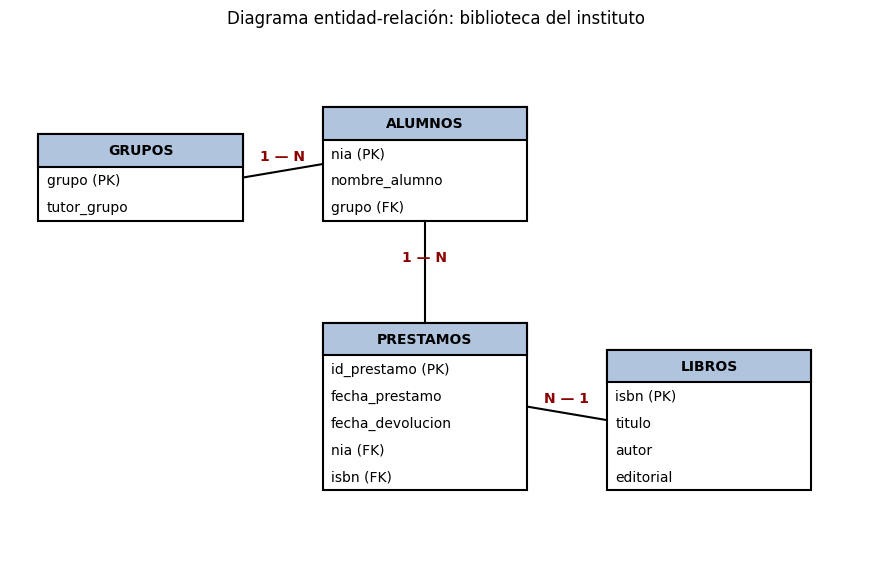

In [18]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

entidades = {
    'grupos':    (0.5, 6.5, ['grupo (PK)', 'tutor_grupo']),
    'alumnos':   (5.5, 6.5, ['nia (PK)', 'nombre_alumno', 'grupo (FK)']),
    'prestamos': (5.5, 1.5, ['id_prestamo (PK)', 'fecha_prestamo', 'fecha_devolucion', 'nia (FK)', 'isbn (FK)']),
    'libros':    (10.5, 1.5, ['isbn (PK)', 'titulo', 'autor', 'editorial']),
}
fig, ax = plt.subplots(figsize=(11, 7))
cajas = {}
for nombre, (x, y, attrs) in entidades.items():
    w, h = 3.6, 0.6 + 0.5 * len(attrs)
    ax.add_patch(Rectangle((x, y), w, h, fill=False, lw=1.5))
    ax.add_patch(Rectangle((x, y + h - 0.6), w, 0.6, color='lightsteelblue', ec='black', lw=1.5))
    ax.text(x + w / 2, y + h - 0.3, nombre.upper(), ha='center', va='center', weight='bold')
    for i, a in enumerate(attrs):
        ax.text(x + 0.15, y + h - 0.6 - 0.5 * (i + 0.5), a, va='center')
    cajas[nombre] = (x, y, w, h)


def relacion(p1, p2, etiqueta):
    ax.plot([p1[0], p2[0]], [p1[1], p2[1]], color='black', lw=1.5)
    ax.text((p1[0] + p2[0]) / 2, (p1[1] + p2[1]) / 2 + 0.2, etiqueta, ha='center', color='darkred', weight='bold')


g, a, p, l = (cajas[k] for k in ('grupos', 'alumnos', 'prestamos', 'libros'))
relacion((g[0] + g[2], g[1] + g[3] / 2), (a[0], a[1] + a[3] / 2), '1 — N')
relacion((a[0] + a[2] / 2, a[1]), (p[0] + p[2] / 2, p[1] + p[3]), '1 — N')
relacion((l[0], l[1] + l[3] / 2), (p[0] + p[2], p[1] + p[3] / 2), 'N — 1')

ax.set_xlim(0, 15)
ax.set_ylim(0, 10)
ax.axis('off')
ax.set_title('Diagrama entidad-relación: biblioteca del instituto')
plt.show()

*Pega aquí tu diagrama o explica dónde está:*

El diagrama está en la celda de código de arriba (matplotlib)

**Entidades colapsadas en la tabla plana:**
- **alumno**: `nia` (PK), `nombre_alumno`, `grupo` (FK)
- **grupo**: `grupo` (PK), `tutor_grupo`
- **libro**: `isbn` (PK), `titulo`, `autor`, `editorial`
- **préstamo**: `id_prestamo` (PK), `fecha_prestamo`, `fecha_devolucion`, `nia` (FK), `isbn` (FK)

**Error de introducción de datos:** el `titulo` del ISBN 978-84-206-7495-1 aparece como «Romancero gitano» y «Romancero Gitano» (préstamo 7). Se corrige unificándolo.

**Cardinalidades:** grupos 1:N alumnos, alumnos 1:N préstamos, libros 1:N préstamos y, entre alumnos y libros, N:M (resuelta por la tabla `prestamos`).

## Ejercicio 2.2 — Matrículas: integridad referencial y granularidad

Secretaría nos pasa tres tablas del curso. Antes de usarlas, hay que comprobar que son coherentes entre sí.

In [19]:
alumnado = pd.DataFrame({
    'nia':       ['N01', 'N02', 'N03', 'N04', 'N05', 'N05', 'N06'],
    'nombre':    ['Ana', 'Bruno', 'Carmen', 'David', 'Eva', 'Eva', 'Fran'],
    'localidad': ['Granada', 'Armilla', 'Granada', 'Ogíjares', 'Granada', 'Granada', 'Motril'],
})

modulos = pd.DataFrame({
    'codigo': ['5104', '5109', '5134', '5144', '5149'],
    'nombre': ['ETCDFM', 'DLCD', 'Modelos de aprendizaje automático', 'IA y aprendizaje automático',
               'Componentes software'],
    'horas_semana': [8, 5, 5, 3, 6],
})

matriculas = pd.DataFrame({
    'nia':    ['N01', 'N01', 'N01', 'N02', 'N02', 'N03', 'N03', 'N03', 'N03', 'N04', 'N05', 'N07', 'N02'],
    'codigo': ['5104', '5109', '5134', '5104', '5109', '5104', '5109', '5134', '5149', '5109', '5104', '5109', '5199'],
    'nota':   [7.5, 8.0, 6.5, 5.0, 4.5, 9.0, 9.5, 8.5, 9.0, 6.0, 7.0, 8.0, 5.5],
})

print(f'alumnado: {len(alumnado)} filas · modulos: {len(modulos)} filas · matriculas: {len(matriculas)} filas')

alumnado: 7 filas · modulos: 5 filas · matriculas: 13 filas


**Parte A — Claves e integridad.**

1. Comprueba si `nia` es una clave primaria válida en `alumnado` y `codigo` en `modulos`. Si no lo es, explica el problema y corrígelo.
2. ¿Cuál es la clave primaria de `matriculas`? Compruébalo.
3. Comprueba la **integridad referencial** de las dos claves foráneas de `matriculas`. Lista las filas huérfanas e indica a qué tabla les falta el registro.
4. ¿Hay algún alumno **sin ninguna matrícula**?

In [20]:
# TODO: claves primarias
print('1. nia único en alumnado:', alumnado['nia'].is_unique)
print(alumnado[alumnado.duplicated('nia', keep=False)])
alumnado = alumnado.drop_duplicates().reset_index(drop=True)
print('nia único tras quitar la fila duplicada:', alumnado['nia'].is_unique)
print('codigo único en modulos:', modulos['codigo'].is_unique)
print('\n2. (nia, codigo) único en matriculas:', not matriculas.duplicated(['nia', 'codigo']).any())

# TODO: integridad referencial
print('\n3. Filas de matriculas sin alumno en alumnado:')
print(matriculas[~matriculas['nia'].isin(alumnado['nia'])])
print('Filas de matriculas sin módulo en modulos:')
print(matriculas[~matriculas['codigo'].isin(modulos['codigo'])])

# TODO: alumnado sin matrícula
print('\n4. Alumnado sin ninguna matrícula:')
print(alumnado[~alumnado['nia'].isin(matriculas['nia'])])

1. nia único en alumnado: False
   nia nombre localidad
4  N05    Eva   Granada
5  N05    Eva   Granada
nia único tras quitar la fila duplicada: True
codigo único en modulos: True

2. (nia, codigo) único en matriculas: True

3. Filas de matriculas sin alumno en alumnado:
    nia codigo  nota
11  N07   5109   8.0
Filas de matriculas sin módulo en modulos:
    nia codigo  nota
12  N02   5199   5.5

4. Alumnado sin ninguna matrícula:
   nia nombre localidad
5  N06   Fran    Motril


**Parte B — Tipos de `merge`.**
Combina `matriculas` con `alumnado` (una vez corregido) usando `how='inner'`, `'left'`, `'right'` y `'outer'`. Para cada caso, anota cuántas filas resultan y explica **por qué** salen esas filas. Usa `indicator=True` para ver de qué tabla procede cada fila.

In [21]:
# TODO: los cuatro tipos de merge
for how in ['inner', 'left', 'right', 'outer']:
    m = matriculas.merge(alumnado, on='nia', how=how, indicator=True)
    print(f'Merge {how.upper()}: {len(m)} filas')
    print(m['_merge'].value_counts().to_string())
    print()

print('INNER: solo las matrículas cuyo alumno existe en alumnado (se pierde la de N07).')
print('LEFT: todas las matrículas; la de N07 queda con nulos en nombre y localidad.')
print('RIGHT: todo el alumnado; N06 aparece sin matrícula (nulos en codigo y nota).')
print('OUTER: la unión de las dos: las 12 que coinciden, la de N07 y N06.')

Merge INNER: 12 filas
_merge
both          12
left_only      0
right_only     0

Merge LEFT: 13 filas
_merge
both          12
left_only      1
right_only     0

Merge RIGHT: 13 filas
_merge
both          12
right_only     1
left_only      0

Merge OUTER: 14 filas
_merge
both          12
left_only      1
right_only     1

INNER: solo las matrículas cuyo alumno existe en alumnado (se pierde la de N07).
LEFT: todas las matrículas; la de N07 queda con nulos en nombre y localidad.
RIGHT: todo el alumnado; N06 aparece sin matrícula (nulos en codigo y nota).
OUTER: la unión de las dos: las 12 que coinciden, la de N07 y N06.


**Parte C — Cuidado con la granularidad.**
Jefatura de estudios pide la **nota media del alumnado de Granada**. Calcúlala de dos formas:

1. Uniendo `matriculas` con `alumnado` y haciendo la media de la columna `nota`.
2. Calculando primero la nota media de **cada alumno** y después la media de esas medias.

¿Salen igual? ¿Por qué? ¿Cuál responde mejor a la pregunta? Explícalo pensando en **qué representa cada fila** en cada cálculo.

In [22]:
# TODO: las dos formas de calcular la nota media
matriculas_alumnos = matriculas.merge(alumnado, on='nia')
granada = matriculas_alumnos[matriculas_alumnos['localidad'] == 'Granada']

media_1 = granada['nota'].mean()
media_2 = granada.groupby('nia')['nota'].mean().mean()
print(f'Forma 1 (media de todas las notas): {media_1:.3f}')
print(f'Forma 2 (media de las medias por alumno): {media_2:.3f}')

Forma 1 (media de todas las notas): 8.125
Forma 2 (media de las medias por alumno): 7.778


*Escribe aquí tus respuestas:*

No salen igual. La primera forma da 8,125 y la segunda 7,78.

En la primera cada fila es una matrícula, así que los alumnos con más módulos pesan más, por ejemplo Carmen tiene 4 notas y Eva solo 1. En la segunda cada fila es un alumno y todos pesan lo mismo. Como la pregunta es por la nota media del alumnado, pienso que la segunda forma es mejor. La primera responde más bien a la nota media de las matrículas de Granada

## Ejercicio 2.3 — Documenta una base de datos real: Chinook

[Chinook](https://github.com/lerocha/chinook-database) es una base de datos de ejemplo de una tienda de música digital (artistas, álbumes, canciones, clientes, facturas…). Es una **base de datos relacional real** en SQLite, con varias tablas y claves foráneas.

La celda siguiente la descarga (solo la primera vez) y abre la conexión.

In [23]:
import urllib.request

URL_CHINOOK = 'https://github.com/lerocha/chinook-database/releases/download/v1.4.5/Chinook_Sqlite.sqlite'
ruta_chinook = Path('chinook.sqlite')

if not ruta_chinook.exists():
    print('Descargando Chinook...')
    urllib.request.urlretrieve(URL_CHINOOK, ruta_chinook)

con = sqlite3.connect(ruta_chinook)
tablas = pd.read_sql("SELECT name FROM sqlite_master WHERE type = 'table' ORDER BY name", con)
tablas

,name
0,Album
1,Artist
2,Customer
3,Employee
4,Genre
5,Invoice
6,InvoiceLine
7,MediaType
8,Playlist
9,PlaylistTrack


**Parte A — Volumetrías y claves.**
Construye un DataFrame `ficha` con **una fila por tabla** y estas columnas:

| tabla | filas | columnas | clave_primaria | claves_foraneas (→ tabla referenciada) |
|---|---|---|---|---|

Pistas:
- `pd.read_sql('SELECT * FROM "Tabla"', con)` carga una tabla entera.
- `PRAGMA table_info("Tabla")` devuelve las columnas; la columna `pk` indica cuáles forman la clave primaria.
- `PRAGMA foreign_key_list("Tabla")` devuelve las claves foráneas.

In [24]:
# TODO: ficha de volumetrías y claves
filas = []
for tabla in tablas['name']:
    info = pd.read_sql(f'PRAGMA table_info("{tabla}")', con)
    fks = pd.read_sql(f'PRAGMA foreign_key_list("{tabla}")', con)
    num_filas = pd.read_sql(f'SELECT COUNT(*) FROM "{tabla}"', con).iloc[0, 0]
    pk = ', '.join(info.loc[info['pk'] > 0, 'name'])
    fk = ', '.join(f"{r['from']} → {r['table']}" for _, r in fks.iterrows())
    filas.append([tabla, num_filas, len(info), pk, fk])
ficha = pd.DataFrame(filas, columns=['tabla', 'filas', 'columnas', 'clave_primaria', 'claves_foraneas'])
ficha

,tabla,filas,columnas,clave_primaria,claves_foraneas
0,Album,347,3,AlbumId,ArtistId → Artist
1,Artist,275,2,ArtistId,
2,Customer,59,13,CustomerId,SupportRepId → Employee
3,Employee,8,15,EmployeeId,ReportsTo → Employee
4,Genre,25,2,GenreId,
5,Invoice,412,9,InvoiceId,CustomerId → Customer
6,InvoiceLine,2240,5,InvoiceLineId,"TrackId → Track, InvoiceId → Invoice"
7,MediaType,5,2,MediaTypeId,
8,Playlist,18,2,PlaylistId,
9,PlaylistTrack,8715,2,"PlaylistId, TrackId","TrackId → Track, PlaylistId → Playlist"


**Parte B — Relaciones.**

1. Escribe la lista de relaciones del esquema con su cardinalidad (por ejemplo: `Artist 1:N Album`).
2. Hay dos tablas que resuelven relaciones **N:M**. ¿Cuáles son y qué entidades relacionan?
3. La tabla `Employee` tiene una clave foránea **hacia sí misma**. ¿Qué representa?
4. ¿Cuál es la **granularidad** de `Invoice` y de `InvoiceLine`? ¿Qué cifra obtendrías si sumaras `Total` de `Invoice` después de unirla con `InvoiceLine`? ¿Sería correcta?

In [25]:
for t in tablas['name']:
    fks = pd.read_sql(f'PRAGMA foreign_key_list("{t}")', con)
    for _, fk in fks.iterrows():
        print(f"{fk['table']} 1:N {t}  ({t}.{fk['from']} -> {fk['table']}.{fk['to']})")

invoice = pd.read_sql('SELECT * FROM "Invoice"', con)
invoice_line = pd.read_sql('SELECT * FROM "InvoiceLine"', con)
print('\nSuma de Invoice.Total:', round(invoice['Total'].sum(), 2))
print('Suma de Total tras unir con InvoiceLine:', round(invoice.merge(invoice_line, on='InvoiceId')['Total'].sum(), 2))

Artist 1:N Album  (Album.ArtistId -> Artist.ArtistId)
Employee 1:N Customer  (Customer.SupportRepId -> Employee.EmployeeId)
Employee 1:N Employee  (Employee.ReportsTo -> Employee.EmployeeId)
Customer 1:N Invoice  (Invoice.CustomerId -> Customer.CustomerId)
Track 1:N InvoiceLine  (InvoiceLine.TrackId -> Track.TrackId)
Invoice 1:N InvoiceLine  (InvoiceLine.InvoiceId -> Invoice.InvoiceId)
Track 1:N PlaylistTrack  (PlaylistTrack.TrackId -> Track.TrackId)
Playlist 1:N PlaylistTrack  (PlaylistTrack.PlaylistId -> Playlist.PlaylistId)
MediaType 1:N Track  (Track.MediaTypeId -> MediaType.MediaTypeId)
Genre 1:N Track  (Track.GenreId -> Genre.GenreId)
Album 1:N Track  (Track.AlbumId -> Album.AlbumId)

Suma de Invoice.Total: 2328.6
Suma de Total tras unir con InvoiceLine: 20848.62


*Escribe aquí tus respuestas:*

1. Las relaciones son estas:
Artist 1:N Album
Album 1:N Track
Genre 1:N Track
MediaType 1:N Track
Customer 1:N Invoice
Invoice 1:N InvoiceLine
Track 1:N InvoiceLine
Playlist 1:N PlaylistTrack
Track 1:N PlaylistTrack
Employee 1:N Customer
Employee 1:N Employee
2. Las tablas que resuelven relaciones N:M son PlaylistTrack, que relaciona Playlist y Track, e InvoiceLine, que relaciona Invoice y Track
3. Representa quién es el jefe de cada empleado. Es una relación dentro de la misma tabla, de jefes y empleados.
4. En Invoice cada fila es una factura y en InvoiceLine cada fila es una canción comprada dentro de una factura. Si sumo Total después de unir las dos tablas me sale 20.848,62 en vez de 2.328,60, porque el total de la factura se repite en cada una de sus líneas. Por eso no sería correcta.

**Parte C — Preguntas con `merge`.**
Carga las tablas que necesites como DataFrames y responde **con pandas** (no con SQL):

1. Los **5 géneros musicales** que más dinero han facturado (`InvoiceLine.UnitPrice × Quantity`).
2. El **país** con más clientes y el país con más facturación.
3. Comprueba la integridad referencial de `Track.GenreId` y de `InvoiceLine.TrackId`. ¿Hay huérfanos?

In [26]:
invoice_line = pd.read_sql('SELECT * FROM "InvoiceLine"', con)
track = pd.read_sql('SELECT * FROM "Track"', con)
genre = pd.read_sql('SELECT * FROM "Genre"', con)
customer = pd.read_sql('SELECT * FROM "Customer"', con)
invoice = pd.read_sql('SELECT * FROM "Invoice"', con)

# 1. géneros que más han facturado
invoice_line['importe'] = invoice_line['UnitPrice'] * invoice_line['Quantity']
facturacion_genero = (invoice_line.merge(track[['TrackId', 'GenreId']], on='TrackId')
                      .merge(genre, on='GenreId')
                      .groupby('Name')['importe'].sum()
                      .sort_values(ascending=False).head(5))
print(facturacion_genero.round(2))

# 2. país con más clientes y con más facturación
clientes_pais = customer['Country'].value_counts()
facturacion_pais = invoice.groupby('BillingCountry')['Total'].sum().sort_values(ascending=False)
print('\nPaís con más clientes:', clientes_pais.index[0], clientes_pais.iloc[0])
print('País con más facturación:', facturacion_pais.index[0], round(facturacion_pais.iloc[0], 2))

# 3. integridad referencial
genero_huerfano = ~track['GenreId'].dropna().isin(genre['GenreId'])
print('\nTrack.GenreId huérfanos:', genero_huerfano.sum(), '| nulos:', track['GenreId'].isna().sum())
print('InvoiceLine.TrackId huérfanos:', (~invoice_line['TrackId'].isin(track['TrackId'])).sum())

Name
Rock                  826.65
Latin                 382.14
Metal                 261.36
Alternative & Punk    241.56
TV Shows               93.53
Name: importe, dtype: float64

País con más clientes: USA 13
País con más facturación: USA 523.06

Track.GenreId huérfanos: 0 | nulos: 0
InvoiceLine.TrackId huérfanos: 0


**Parte D — Diagrama.**
Dibuja el diagrama entidad-relación de Chinook (puedes omitir los atributos que no sean claves). Herramientas: a mano, [draw.io](https://app.diagrams.net) o [dbdiagram.io](https://dbdiagram.io).

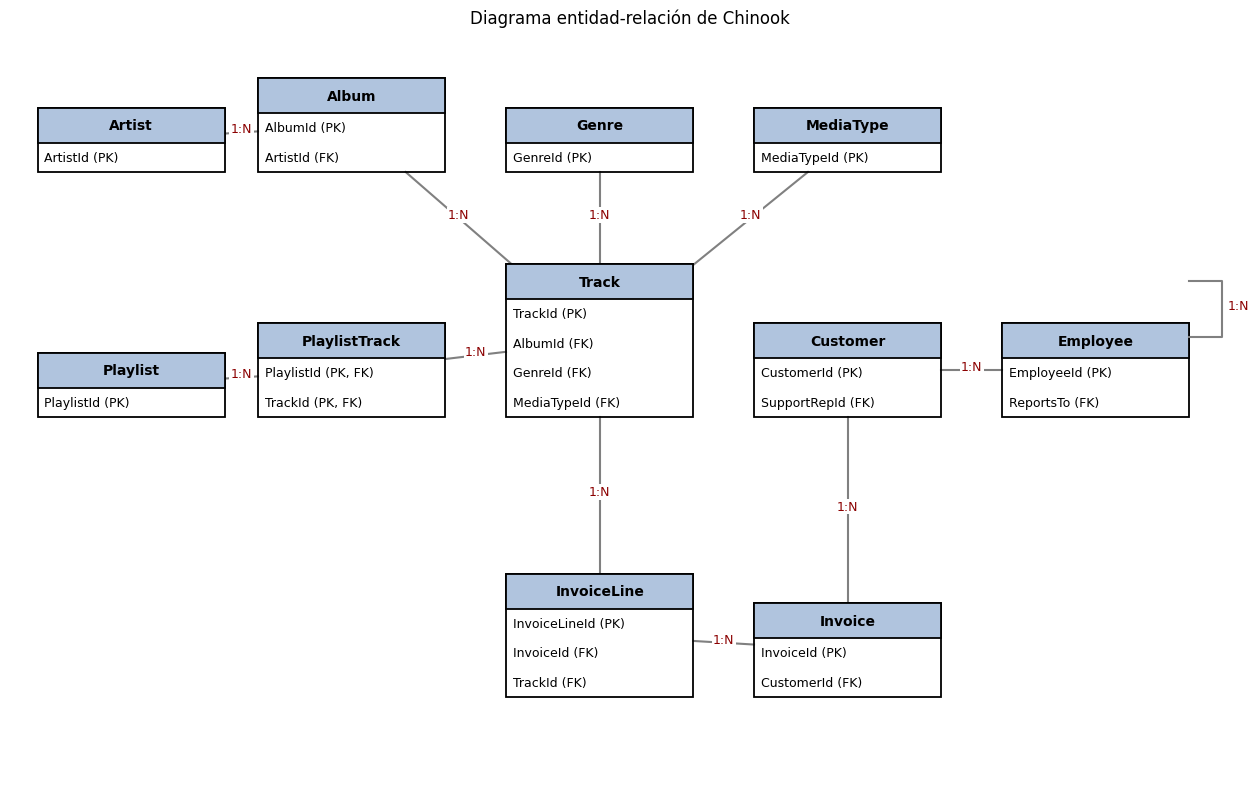

In [27]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

tablas_er = {
    'Artist':        (0.5, 9.0,  ['ArtistId (PK)']),
    'Album':         (4.5, 9.0,  ['AlbumId (PK)', 'ArtistId (FK)']),
    'Genre':         (9.0, 9.0,  ['GenreId (PK)']),
    'MediaType':     (13.5, 9.0, ['MediaTypeId (PK)']),
    'Track':         (9.0, 5.5,  ['TrackId (PK)', 'AlbumId (FK)', 'GenreId (FK)', 'MediaTypeId (FK)']),
    'Playlist':      (0.5, 5.5,  ['PlaylistId (PK)']),
    'PlaylistTrack': (4.5, 5.5,  ['PlaylistId (PK, FK)', 'TrackId (PK, FK)']),
    'InvoiceLine':   (9.0, 1.5,  ['InvoiceLineId (PK)', 'InvoiceId (FK)', 'TrackId (FK)']),
    'Invoice':       (13.5, 1.5, ['InvoiceId (PK)', 'CustomerId (FK)']),
    'Customer':      (13.5, 5.5, ['CustomerId (PK)', 'SupportRepId (FK)']),
    'Employee':      (18.0, 5.5, ['EmployeeId (PK)', 'ReportsTo (FK)']),
}
fig, ax = plt.subplots(figsize=(16, 10))
cajas = {}
for nombre, (x, y, attrs) in tablas_er.items():
    w, h = 3.4, 0.5 + 0.42 * len(attrs)
    ax.add_patch(Rectangle((x, y), w, h, fill=False, lw=1.3))
    ax.add_patch(Rectangle((x, y + h - 0.5), w, 0.5, color='lightsteelblue', ec='black', lw=1.3))
    ax.text(x + w / 2, y + h - 0.25, nombre, ha='center', va='center', weight='bold')
    for i, a in enumerate(attrs):
        ax.text(x + 0.12, y + h - 0.5 - 0.42 * (i + 0.5), a, va='center', fontsize=9)
    cajas[nombre] = (x, y, w, h)

def borde(n, destino):
    x, y, w, h = cajas[n]
    dx, dy = destino[0] - (x + w / 2), destino[1] - (y + h / 2)
    t = min((w / 2) / abs(dx) if dx else 1e9, (h / 2) / abs(dy) if dy else 1e9)
    return x + w / 2 + dx * t, y + h / 2 + dy * t


def centro(n):
    x, y, w, h = cajas[n]
    return x + w / 2, y + h / 2

relaciones = [
    ('Artist', 'Album', '1:N'), ('Album', 'Track', '1:N'), ('Genre', 'Track', '1:N'),
    ('MediaType', 'Track', '1:N'), ('Playlist', 'PlaylistTrack', '1:N'), ('Track', 'PlaylistTrack', '1:N'),
    ('Track', 'InvoiceLine', '1:N'), ('Invoice', 'InvoiceLine', '1:N'), ('Customer', 'Invoice', '1:N'),
    ('Employee', 'Customer', '1:N'), ('Employee', 'Employee', '1:N'),
]
for a, b, card in relaciones:
    if a == b:
        x, y, w, h = cajas[a]
        ax.plot([x + w, x + w + 0.6, x + w + 0.6, x + w], [y + h - 0.2, y + h - 0.2, y + h + 0.6, y + h + 0.6], color='gray')
        ax.text(x + w + 0.7, y + h + 0.2, card, color='darkred', fontsize=9)
        continue
    (x1, y1), (x2, y2) = borde(a, centro(b)), borde(b, centro(a))
    ax.plot([x1, x2], [y1, y2], color='gray', zorder=0)
    ax.text((x1 + x2) / 2, (y1 + y2) / 2, card, color='darkred', fontsize=9, ha='center',
            bbox=dict(fc='white', ec='none', pad=1))

ax.set_xlim(0, 22.5)
ax.set_ylim(0, 11)
ax.axis('off')
ax.set_title('Diagrama entidad-relación de Chinook')
plt.show()

*Pega aquí tu diagrama o explica dónde está:*

El diagrama está en la celda de código de arriba, hecho con matplotlib

---
# Sesión 3 — Formatos, carga y repositorios

## Ejercicio 3.1 — Datos abiertos del INE: la población de Granada

El **Instituto Nacional de Estadística** publica sus tablas en CSV. Vamos a usar la tabla **2852 — Población por provincias y sexo** (cifras del padrón):

```
https://www.ine.es/jaxiT3/files/t/es/csv_bdsc/2852.csv
```

Si la descarga directa falla, entra en <https://www.ine.es/jaxiT3/Tabla.htm?t=2852>, pulsa el botón de descarga, elige **CSV: separado por ;** y guarda el fichero en esta carpeta.

**Parte A — Carga ingenua.**
Carga el fichero con `pd.read_csv()` **sin ningún parámetro** y observa el resultado. Describe todos los problemas que veas.

In [28]:
URL_INE = 'https://www.ine.es/jaxiT3/files/t/es/csv_bdsc/2852.csv'

df_ine_mal = pd.read_csv(URL_INE)
df_ine_mal.head()

ParserError: Error tokenizing data. C error: Expected 1 fields in line 626, saw 2


*Problemas detectados en la carga ingenua:*

- El separador de campos es el punto y coma, así que pandas no separa las columnas y lo mete todo en una sola.
- Los números llevan el punto como separador de miles, por lo que la columna Total se queda como texto en vez de numérica
- Los decimales usan coma y los nulos pueden venir marcados con algo como dos puntos seguidos, que pandas no reconoce como nulo.
- La columna Provincias mezcla el código y el nombre, por ejemplo 18 Granada
- Los acentos pueden salir mal si la codificación no es la que pandas espera.

**Parte B — Carga correcta.**
Vuelve a cargarlo con los parámetros adecuados (`sep`, `thousands`, `decimal`, `encoding`, `na_values`, `dtype`…) para que la columna `Total` sea numérica. Después:

1. La columna `Provincias` mezcla el **código** y el **nombre** de la provincia (por ejemplo, `18 Granada`). Sepárala en dos columnas, `cod_provincia` y `provincia`.
2. Asigna a cada columna su `dtype` adecuado.
3. Muestra la **evolución de la población de Granada** (ambos sexos) en los años disponibles.
4. ¿En qué año tuvo Granada más población? ¿Cuántos habitantes más o menos tiene ahora que el primer año de la serie?

In [ ]:
df_ine = pd.read_csv(URL_INE, sep=';', thousands='.', decimal=',', encoding='utf-8-sig', na_values=['..', '-'])

df_ine[['cod_provincia', 'provincia']] = df_ine['Provincias'].str.extract(r'^(\d+)\s+(.+)$')
df_ine['anio'] = df_ine['Periodo'].astype(str).str.extract(r'(\d{4})')[0]

df_ine = df_ine.astype({
    'cod_provincia': 'string',
    'provincia': 'category',
    'Sexo': 'category',
    'anio': 'Int64',
    'Total': 'Int64',
})
print(df_ine.dtypes)

granada = df_ine[(df_ine['cod_provincia'] == '18') & (df_ine['Sexo'] == 'Ambos sexos')].sort_values('anio')
print(granada[['anio', 'Total']].to_string(index=False))

maximo = granada.loc[granada['Total'].idxmax()]
diferencia = granada['Total'].iloc[-1] - granada['Total'].iloc[0]
print(f"Año con más población: {maximo['anio']} ({maximo['Total']:,} habitantes)")
print(f"Diferencia entre el último y el primer año: {diferencia:,} habitantes")

**Preguntas:**

1. ¿Cuál es la **granularidad** de la tabla? ¿Qué filas tendrías que quitar para no contar dos veces a la misma población al sumar?
2. ¿Por qué el INE usa el punto como separador de miles y `;` como separador de campos? ¿Qué pasaría si usara `,` como separador de campos?

*Escribe aquí tus respuestas:*

1. Cada fila es una combinación de provincia, sexo y periodo. Para no contar dos veces a la misma población tendría que quitar las filas del total nacional y las de ambos sexos, o quedarme solo con hombres y mujeres.
2. Porque en España la coma se usa como separador decimal y el punto como separador de miles, así que el INE usa el punto y coma para separar los campos. Si usara la coma, los decimales partirían las filas en más columnas y la tabla se descuadraría

## Ejercicio 3.2 — Caso práctico: la red de calidad del aire

Una red de estaciones de calidad del aire de la provincia de Granada guarda su información en **cinco ficheros de cinco formatos distintos**, porque cada parte la genera un sistema diferente. *(Los datos son simulados.)*

| Fichero | Formato | Contenido |
|---|---|---|
| `aire/estaciones.xml` | XML | Estaciones de medida |
| `aire/mediciones_enero.csv` | CSV | Mediciones diarias de enero |
| `aire/mediciones_febrero.json` | JSON | Mediciones diarias de febrero |
| `aire/contaminantes.xlsx` | Excel (2 hojas) | Contaminantes y su valor límite · índice de calidad del aire |
| `aire/incidencias.db` | SQLite | Incidencias de mantenimiento de las estaciones |

Ejecuta la celda para generar los ficheros.

In [ ]:
# ── Generación de los ficheros (no hace falta que entiendas este código) ─────
carpeta = Path('aire')
carpeta.mkdir(exist_ok=True)
rng = np.random.default_rng(2027)

estaciones = [
    ('GR01', 'Granada Norte', 'Granada', 'tráfico', 37.1969, -3.6121),
    ('GR02', 'Palacio de Congresos', 'Granada', 'fondo urbano', 37.1653, -3.5987),
    ('GR03', 'Armilla', 'Armilla', 'fondo suburbano', 37.1414, -3.6283),
    ('GR04', 'Motril', 'Motril', 'industrial', 36.7471, -3.5179),
]
xml = ['<?xml version="1.0" encoding="UTF-8"?>', '<red nombre="Red provincial de calidad del aire">']
for cod, nom, mun, tipo, lat, lon in estaciones:
    xml.append(f'  <estacion codigo="{cod}">\n    <nombre>{nom}</nombre>\n    <municipio>{mun}</municipio>\n'
               f'    <tipo>{tipo}</tipo>\n    <lat>{lat}</lat>\n    <lon>{lon}</lon>\n  </estacion>')
xml.append('</red>')
(carpeta / 'estaciones.xml').write_text('\n'.join(xml), encoding='utf-8')

def mediciones(mes, dias):
    filas = []
    for cod, *_ in estaciones:
        base = {'GR01': 42, 'GR02': 28, 'GR03': 22, 'GR04': 30}[cod]
        for d in range(1, dias + 1):
            filas.append({
                'estacion': cod, 'fecha': pd.Timestamp(2027, mes, d),
                'no2': round(max(rng.normal(base, 9), 3), 1),
                'pm10': round(max(rng.normal(base * 0.8, 10), 2), 1),
                'o3': round(max(rng.normal(70 - base * 0.6, 12), 5), 1),
            })
    return pd.DataFrame(filas)

ene = mediciones(1, 31)
ene.loc[rng.choice(len(ene), 6, replace=False), 'pm10'] = np.nan     # el analizador falló
ene.loc[17, 'no2'] = -999                                           # código de error del sensor
ene_csv = ene.assign(fecha=ene['fecha'].dt.strftime('%d/%m/%Y')).rename(columns={
    'estacion': 'Estación', 'fecha': 'Fecha', 'no2': 'NO2 (µg/m³)', 'pm10': 'PM10 (µg/m³)', 'o3': 'O3 (µg/m³)'})
ene_csv.to_csv(carpeta / 'mediciones_enero.csv', sep=';', decimal=',', index=False,
               na_rep='-', encoding='latin-1')

feb = mediciones(2, 28)
feb_json = [{'estacion': r.estacion, 'fecha': r.fecha.strftime('%Y-%m-%d'),
             'medidas': {'NO2': r.no2, 'PM10': r.pm10, 'O3': r.o3}} for r in feb.itertuples()]
(carpeta / 'mediciones_febrero.json').write_text(json.dumps(feb_json, ensure_ascii=False), encoding='utf-8')

with pd.ExcelWriter(carpeta / 'contaminantes.xlsx') as xls:
    pd.DataFrame({
        'codigo': ['no2', 'pm10', 'o3'],
        'nombre': ['Dióxido de nitrógeno', 'Partículas < 10 µm', 'Ozono'],
        'unidad': ['µg/m³'] * 3,
        'valor_limite_diario': [50, 45, 100],
    }).to_excel(xls, sheet_name='contaminantes', index=False)
    pd.DataFrame({
        'nivel': ['Buena', 'Razonablemente buena', 'Regular', 'Desfavorable', 'Muy desfavorable'],
        'no2_hasta': [40, 90, 120, 230, 340],
    }).to_excel(xls, sheet_name='indice_calidad', index=False)

ruta_db = carpeta / 'incidencias.db'
ruta_db.unlink(missing_ok=True)
with sqlite3.connect(ruta_db) as c:
    c.execute('CREATE TABLE incidencias (id INTEGER PRIMARY KEY, estacion TEXT, fecha TEXT, tipo TEXT, descripcion TEXT)')
    c.executemany('INSERT INTO incidencias VALUES (?, ?, ?, ?, ?)', [
        (1, 'GR01', '2027-01-18', 'avería', 'Fallo del analizador de NO2'),
        (2, 'GR03', '2027-01-25', 'calibración', 'Calibración programada'),
        (3, 'GR04', '2027-02-10', 'avería', 'Corte de suministro eléctrico'),
        (4, 'GR05', '2027-02-14', 'instalación', 'Montaje de la nueva estación de Baza'),
        (5, 'GR02', '2027-02-21', 'calibración', 'Calibración programada'),
    ])
c.close()

for f in sorted(carpeta.iterdir()):
    print(f'{f.name:28s} {f.stat().st_size:>8,} bytes')

**Parte A — Carga.**
Carga cada fichero con la función `read_*` adecuada y los parámetros necesarios. Abre antes los ficheros de texto (CSV, JSON y XML) con VS Code para ver cómo están escritos: separador, decimales, codificación, cómo se marcan los nulos, estructura…

Al terminar debes tener: `df_estaciones`, `df_enero`, `df_febrero`, `df_contaminantes`, `df_indice` y `df_incidencias`.

In [ ]:
df_estaciones = pd.read_xml('aire/estaciones.xml')

df_enero = pd.read_csv('aire/mediciones_enero.csv', sep=';', decimal=',', encoding='latin-1', na_values='-')

with open('aire/mediciones_febrero.json', encoding='utf-8') as f:
    df_febrero = pd.json_normalize(json.load(f))

df_contaminantes = pd.read_excel('aire/contaminantes.xlsx', sheet_name='contaminantes')
df_indice = pd.read_excel('aire/contaminantes.xlsx', sheet_name='indice_calidad')

with sqlite3.connect('aire/incidencias.db') as con_aire:
    df_incidencias = pd.read_sql('SELECT * FROM incidencias', con_aire)

print(df_enero.head(3))
print(df_febrero.head(3))

**Parte B — Integración.**
Une enero y febrero en un único DataFrame `mediciones` con las columnas `estacion`, `fecha`, `no2`, `pm10` y `o3`. Las columnas deben tener **el mismo nombre y el mismo `dtype`** en los dos meses.

Revisa después la calidad de la unión:

1. ¿Cuántos valores nulos hay en cada contaminante? ¿De qué mes vienen?
2. Hay un valor **imposible** escondido en los datos. Encuéntralo, explica qué significa y conviértelo en nulo.
3. Comprueba que no hay mediciones duplicadas (misma estación y misma fecha).

In [ ]:
# integración de enero y febrero
df_enero.columns = ['estacion', 'fecha', 'no2', 'pm10', 'o3']
df_enero['fecha'] = pd.to_datetime(df_enero['fecha'], format='%d/%m/%Y')

df_febrero.columns = ['estacion', 'fecha', 'no2', 'pm10', 'o3']
df_febrero['fecha'] = pd.to_datetime(df_febrero['fecha'], format='%Y-%m-%d')

mediciones = pd.concat([df_enero.assign(mes='enero'), df_febrero.assign(mes='febrero')], ignore_index=True)
print(mediciones.dtypes)

# revisión de calidad
print('\nNulos por contaminante y mes:')
print(mediciones.groupby('mes')[['no2', 'pm10', 'o3']].apply(lambda g: g.isna().sum()))

print('\nValores imposibles (negativos):')
print(mediciones[(mediciones[['no2', 'pm10', 'o3']] < 0).any(axis=1)])
mediciones = mediciones.drop(columns='mes')
mediciones[['no2', 'pm10', 'o3']] = mediciones[['no2', 'pm10', 'o3']].mask(mediciones[['no2', 'pm10', 'o3']] < 0)

print('\nDuplicados (estación y fecha):', mediciones.duplicated(['estacion', 'fecha']).sum())

*Notas de la revisión de calidad:*

1. Hay 6 nulos, todos en pm10 y todos de enero. En el CSV venían marcados con un guion. Febrero no tiene ninguno
2. El valor imposible es un NO2 de -999 en GR01 el 18/01. Es el código de error del sensor y coincide con la incidencia 1, que es un fallo del analizador de NO2 ese mismo día. Lo convierto en nulo.
3. No hay mediciones duplicadas

**Parte C — Entidades y documentación.**

1. Identifica las **entidades** del sistema, sus **claves primarias** y las **relaciones** entre ellas (con su cardinalidad).
2. Comprueba la **integridad referencial** de `mediciones.estacion` y de `incidencias.estacion` frente a `estaciones`. ¿Qué ocurre con la incidencia 4? ¿Es un error o tiene explicación?
3. Construye una tabla de **volumetrías**: filas, columnas y memoria de cada DataFrame.

In [ ]:
# integridad referencial
huerfanas_med = ~mediciones['estacion'].isin(df_estaciones['codigo'])
huerfanas_inc = ~df_incidencias['estacion'].isin(df_estaciones['codigo'])
print('Mediciones huérfanas:', huerfanas_med.sum())
print('Incidencias huérfanas:')
print(df_incidencias[huerfanas_inc])

# volumetrías
dfs = {'estaciones': df_estaciones, 'mediciones': mediciones, 'contaminantes': df_contaminantes,
       'indice': df_indice, 'incidencias': df_incidencias}
volumetrias = pd.DataFrame({
    'filas': {k: len(v) for k, v in dfs.items()},
    'columnas': {k: v.shape[1] for k, v in dfs.items()},
    'memoria_KB': {k: round(v.memory_usage(deep=True).sum() / 1024, 1) for k, v in dfs.items()},
})
volumetrias

*Entidades, claves y relaciones:*

Estación: clave primaria codigo.
Medición: clave primaria formada por estacion y fecha. La estacion es clave foránea a Estación.
Contaminante: clave primaria codigo, con la unidad y el valor límite diario.
Índice de calidad: clave primaria nivel, con el límite de NO2 de cada nivel.
Incidencia: clave primaria id. La estacion es clave foránea a Estación

Las relaciones son Estación 1:N Medición y Estación 1:N Incidencia. Contaminante e Índice de calidad no tienen clave foránea, sirven para interpretar las mediciones

La incidencia 4 es de la estación GR05, que no está en el XML de estaciones. No creo que sea un error, porque la propia incidencia dice que es el montaje de la nueva estación de Baza, así que todavía no está dada de alta en el fichero de estaciones.

**Parte D — Resultado.**

1. Añade a `mediciones` el **nombre** y el **tipo** de cada estación.
2. Añade una columna `calidad_no2` con el nivel del índice de calidad según el NO2 (hoja `indice_calidad`), como **categórica ordinal**. Pista: `pd.cut()` con los límites de la hoja.
3. Calcula, para cada estación, cuántos días **superó el valor límite diario** de cada contaminante.
4. Guarda el resultado en **Parquet** (`aire/mediciones_integradas.parquet`) y vuelve a leerlo. ¿Se conservan los `dtypes`? ¿Pasaría lo mismo si lo guardaras en CSV?

In [ ]:
# D.1 nombre y tipo de cada estación
mediciones = mediciones.merge(
    df_estaciones[['codigo', 'nombre', 'tipo']].rename(columns={'codigo': 'estacion', 'nombre': 'nombre_estacion'}),
    on='estacion', how='left')

# D.2 calidad según NO2
niveles = pd.CategoricalDtype(df_indice['nivel'].tolist(), ordered=True)
limites = [0] + df_indice['no2_hasta'].tolist()
mediciones['calidad_no2'] = pd.cut(mediciones['no2'], bins=limites, labels=df_indice['nivel'], include_lowest=True).astype(niveles)
print(mediciones['calidad_no2'].value_counts(sort=False))

# D.3 días que superan el valor límite diario
limite = df_contaminantes.set_index('codigo')['valor_limite_diario']
superan = pd.DataFrame({c: mediciones[c] > limite[c] for c in ['no2', 'pm10', 'o3']})
superan['estacion'] = mediciones['estacion']
print('\nDías sobre el límite:')
print(superan.groupby('estacion').sum())

# D.4 Parquet y CSV
mediciones.to_parquet('aire/mediciones_integradas.parquet')
leido = pd.read_parquet('aire/mediciones_integradas.parquet')
print('\nParquet conserva dtypes:', (leido.dtypes == mediciones.dtypes).all())

mediciones.to_csv('aire/mediciones_integradas.csv', index=False)
leido_csv = pd.read_csv('aire/mediciones_integradas.csv')
print('CSV conserva dtypes:', (leido_csv.dtypes == mediciones.dtypes).all())
print(leido_csv.dtypes[['fecha', 'calidad_no2']])

**Preguntas:**

1. Si fueras responsable de esta red, ¿en qué **formato único** guardarías todos estos datos a partir de ahora? Justifícalo.
2. ¿Qué ventajas tiene que las estaciones estén en una tabla aparte, en lugar de repetir su nombre y su tipo en cada medición?

*Escribe aquí tus respuestas:*

1. Guardaría todo en una base de datos relacional, por ejemplo SQLite. Los datos ya tienen claves y relaciones entre estaciones, mediciones e incidencias, y así dejo de tener cinco formatos distintos. Para los análisis pesados exportaría a Parquet.
2. El nombre y el tipo de cada estación se guardan una sola vez. Se ocupa menos espacio, si cambia un dato solo lo cambio en un sitio y no hay riesgo de que la misma estación aparezca escrita de dos formas

Sobre la parte D: con Parquet se conservan los tipos de datos, pero con CSV no, porque la fecha y la calidad del NO2 vuelven como texto y se pierde la categoría ordenada. En NO2 solo salen los niveles Buena y Razonablemente buena. GR01, la de tráfico, es la única estación que supera el límite de NO2, con 10 días, y también la que más supera el de PM10, con 8 días.

## Ejercicio 3.3 — Repositorios de datos: ¿de dónde vienen y qué nos cuentan?

Un buen repositorio no solo da el fichero: también da **metadatos** (quién lo creó, cuándo, con qué licencia, qué significa cada columna…). Sin ellos es difícil saber si un dataset es fiable o si se puede usar.

**Parte A — Investiga.**
Busca un dataset sobre **el mismo tema** en tres repositorios distintos. Elige un tema que te interese (por ejemplo: calidad del aire, accidentes de tráfico, rendimiento académico, consumo eléctrico, turismo…). Al menos uno de los tres debe ser un portal de **datos abiertos públicos** ([datos.gob.es](https://datos.gob.es), [Junta de Andalucía](https://www.juntadeandalucia.es/datosabiertos/portal.html), [INE](https://www.ine.es), [Eurostat](https://ec.europa.eu/eurostat/data/database)…) y otro debe ser [Kaggle](https://www.kaggle.com/datasets), [UCI](https://archive.ics.uci.edu) o [Hugging Face](https://huggingface.co/datasets).

| Aspecto | Dataset 1 | Dataset 2 | Dataset 3 |
|---|---|---|---|
| Nombre y enlace | [Air Quality (UCI)](https://archive.ics.uci.edu/dataset/360/air+quality) | [Calidad del aire. Datos diarios desde 2001](https://datos.gob.es/en/catalogo/l01280796-calidad-del-aire-datos-diarios-desde-2001) | [DelhiPollDataset](https://huggingface.co/datasets/sachin-iitd/DelhiPollDataset) |
| Repositorio | UCI | datos.gob.es | Hugging Face |
| Quién lo publica | S. De Vito | Ayuntamiento de Madrid | IIT Delhi |
| Licencia | CC BY 4.0 | CC BY 4.0 | CC BY 4.0 |
| Fecha de la última actualización | Donado en marzo de 2016, con datos de 2004 a 2005 | Se actualiza cada mes, los ficheros más recientes son de octubre de 2026 | Datos de noviembre de 2020 a enero de 2021 |
| Formato(s) de descarga | CSV y XLSX | CSV, JSON, XML y TXT | CSV |
| Filas × columnas (aprox.) | 9358 × 15 | Un fichero por año, no indica las filas | 10 columnas, no indica las filas |
| ¿Describe el significado de cada columna? | Sí, tiene una tabla de variables | No lo veo en la página | Solo dice los nombres de los campos |
| ¿Explica cómo se recogieron los datos? | Sí, con sensores de gas en una ciudad italiana | Dice que vienen de las estaciones de control y que el dato diario es la media de las 24 horas | No, solo manda a la web del proyecto |
| Naturaleza (estructurado / semi / no estructurado) | Estructurado | Estructurado | Estructurado |

*Edita la tabla en la celda de arriba o responde aquí:*

**Parte B — Carga uno de ellos.**
Carga en pandas uno de los tres datasets (desde su URL, desde el fichero descargado o con la librería del repositorio) y muestra: dimensiones, `dtypes` y las primeras filas. Corrige los `dtypes` que no sean adecuados.

In [ ]:
ruta_aire = Path('AirQualityUCI.csv')

if ruta_aire.exists():
    df_aire = pd.read_csv(ruta_aire, sep=';', decimal=',', na_values=-200)
    df_aire = df_aire.dropna(axis=1, how='all').dropna(how='all')
    df_aire['fecha'] = pd.to_datetime(df_aire.pop('Date') + ' ' + df_aire.pop('Time'), format='%d/%m/%Y %H.%M.%S')
    print(df_aire.shape)
    print(df_aire.dtypes)
    display(df_aire.head())
else:
    print('Descarga el zip de UCI Air Quality y deja AirQualityUCI.csv en esta carpeta')

**Preguntas:**

1. ¿Cuál de los tres datasets elegirías para un proyecto real? ¿Por qué? Ten en cuenta la licencia, la documentación y la calidad aparente de los datos.
2. ¿Qué metadatos echas en falta en alguno de ellos?
3. ¿Qué diferencia hay entre una licencia **CC BY 4.0** y una **CC BY-NC**? ¿Podrías usar un dataset CC BY-NC para entrenar un modelo que vaya a vender una empresa?

*Escribe aquí tus respuestas:*

1. Elegiría el de UCI. Tiene una licencia clara, CC BY 4.0, una ficha que explica las variables y el periodo que cubre, y lo puedo citar sin problema. Los otros dos también son CC BY 4.0, pero el de Madrid no enseña qué significa cada columna y el de Hugging Face tampoco explica los campos ni cómo se recogieron
2. En el de datos.gob.es echo en falta una descripción de las columnas, en el de Hugging Face echo en falta cómo se recogieron los datos y qué significa cada campo, y en el de UCI echo en falta datos más recientes, porque solo cubre un año, de 2004 a 2005
3. CC BY 4.0 deja usar y modificar el dataset, incluso con fines comerciales, siempre que se cite al autor. CC BY-NC no permite el uso comercial. Por eso no podría usar un dataset CC BY-NC para entrenar un modelo que vaya a vender una empresa.